# Ансамблевые методы: прогнозирование оттока клиентов

## 1. Титульный лист

**Дисциплина:** Машинное обучение и искусственный интеллект  
**Модуль 3:** Ансамблевые методы (Базовый и продвинутый уровень)  
**Датасет:** *Telco Customer Churn*  
**Выполнила:** Володина Александра Александровна  
**Группа:** ПКТб-23-1  
**Преподаватель:** Спирин Игорь Сергеевич  
**Ссылка на репозиторий:** [VolodinaAlexandra/ml-course-volodina](https://github.com/VolodinaAlexandra/ml-course-volodina)  
**Путь к модулю:** module-3-churn/notebook.ipynb  
**Дата сдачи:** 2026-10-27  
**Учебный год:** 2026/2027

## 2. Введение

**Задача:** бинарная классификация — предсказать уход клиента (Churn=Yes) или его сохранение (Churn=No). Ранжирование риска помогает выбрать клиентов для программы удержания, но само по себе не показывает эффект скидки или звонка.

**Ансамбль** объединяет несколько моделей, ошибки которых могут частично компенсироваться. Random Forest усредняет разные деревья, а бустинг последовательно добавляет деревья, уменьшающие ошибки текущей композиции. По сравнению с отдельным деревом ансамбли могут уменьшать разброс или систематическую ошибку; преимущество обязательно проверяется на отложенных данных.

**Основная метрика — ROC-AUC:** оценивает ранжирование риска без выбора порога. Из-за доли No около 73,5% одна Accuracy недостаточна. F1 показывает баланс Precision и Recall при заданном пороге, а Recall помогает оценить число пропущенных уходов. Рабочий порог должен учитывать стоимость лишнего контакта и пропущенного ухода; этих затрат в датасете нет.

**Цели работы:**

1. Обучить Random Forest, XGBoost, LightGBM и CatBoost и сравнить качество и время.
2. Оптимизировать LightGBM через Optuna на кросс-валидации обучающей части.
3. Интерпретировать модель через SHAP, сохранить артефакты и проверить инференс.

## 3. Теоретическая часть

### Ансамбль

Ансамбль объединяет ответы нескольких базовых моделей. Отдельное дерево чувствительно к случайным деталям обучающей выборки. Усреднение разных деревьев может снизить эту чувствительность. Последовательное исправление ошибок позволяет описать более сложную зависимость, чем одно слабое дерево. Улучшение зависит от разнообразия ошибок и настройки сложности, поэтому ансамбль не гарантирует выигрыш в любой задаче.

### Bagging и Boosting

В bagging модели обучаются на разных bootstrap-выборках, затем их ответы усредняются. Это главным образом уменьшает разброс и допускает параллельное обучение. В boosting новые модели добавляются последовательно с учётом ошибок текущей композиции. Такая схема уменьшает систематическую ошибку, но требует настройки глубины, числа шагов и темпа обучения. В классификации усредняются вероятности либо суммарный score преобразуется в вероятность.

$$H(x)=\frac{1}{M}\sum_{i=1}^{M}h_i(x)\quad\text{(Bagging)}$$

$$H(x)=\sum_{i=1}^{M}\alpha_i h_i(x)\quad\text{(Boosting)}$$

Здесь $M$ — число базовых моделей, $h_i$ — их ответы, $\alpha_i$ — веса. Для бинарного градиентного бустинга сумма часто задаёт логит, преобразуемый сигмоидой.

### Random Forest

Случайный лес строит деревья на bootstrap-выборках. При каждом разбиении рассматривается случайное подмножество признаков. Эти два источника случайности уменьшают сходство деревьев и позволяют снизить разброс ансамбля. Глубина, минимальный размер листа и число деревьев управляют сложностью и устойчивостью.

### Градиентный бустинг

Градиентный бустинг добавляет очередное дерево так, чтобы уменьшить текущую функцию потерь. XGBoost использует регуляризацию и производные для выбора разбиений. LightGBM эффективно ищет разбиения по гистограммам и обычно растит дерево по листьям. CatBoost поддерживает категориальные признаки и ordered boosting для снижения смещения. В этой работе все модели получают одинаковые LabelEncoder-коды согласно заданию, поэтому нативная обработка категорий CatBoost отдельно не проверяется.

### Optuna

Optuna многократно вызывает objective-функцию в заданном пространстве параметров. TPE sampler использует результаты прошлых испытаний для поиска перспективных областей. Это экономнее полного перебора при большом числе параметров. Фиксированный seed и одинаковые CV-блоки помогают воспроизводимости; отложенный тест не используется в objective.

### SHAP

SHAP распределяет отличие ответа модели от базового ответа между признаками на основе значений Шепли. Summary plot показывает вклады по многим клиентам, а bar plot — средние абсолютные вклады. Waterfall объясняет один прогноз по шагам. Dependence plot связывает значение одного признака с его вкладом. Здесь объясняются **логиты**, поэтому SHAP нельзя называть прямой прибавкой к вероятности или причинным влиянием.

| Алгоритм | Подход | Основные настройки | Категории в работе |
|---|---|---|---|
| Random Forest | Bagging | глубина, размер листа, число деревьев | целочисленные коды |
| XGBoost | Boosting | глубина, темп, L1/L2, подвыборки | целочисленные коды |
| LightGBM | Boosting | листья, глубина, регуляризация | целочисленные коды |
| CatBoost | Boosting | глубина, темп, итерации | целочисленные коды |

**Stacking** обучает метамодель на прогнозах базовых моделей, полученных вне их обучающих блоков. Без такого разделения метамодель может переобучиться на слишком точных обучающих ответах.

## 4. Описание данных

**Основной источник:** [Kaggle Telco Customer Churn](https://www.kaggle.com/datasets/blastchar/telco-customer-churn). Для скачивания использована открытая [копия IBM](https://github.com/IBM/telco-customer-churn-on-icp4d/blob/master/data/Telco-Customer-Churn.csv), сохранённая как data/telco_churn.csv.

**Структура:** 7043 клиента, 21 столбец: 19 признаков, customerID и целевая Churn. По смыслу три непрерывных числовых признака — tenure, MonthlyCharges, TotalCharges; остальные 16 — категории, включая бинарный SeniorCitizen. В исходном CSV TotalCharges хранится текстом.

| Столбец | Исходный тип | Содержание | Пропуски |
|---|---|---|---:|
| customerID | строка | идентификатор, исключается | 0 |
| gender | строка | пол | 0 |
| SeniorCitizen | целое 0/1 | признак пожилого клиента | 0 |
| tenure | целое | месяцев с компанией | 0 |
| MonthlyCharges | вещественное | ежемесячный платёж | 0 |
| TotalCharges | строка → вещественное | сумма платежей | 11 пустых строк (0,156%) |
| Contract | строка | тип контракта | 0 |
| Churn | строка | **целевая** Yes/No | 0 |

**Классы:** No — 5174 клиента (73,46%), Yes — 1869 (26,54%). Описание данных: data/churn_info.md.

In [1]:
# Импортируем средства анализа, обучения и сохранения артефактов.
import json  # Подключаем json
import time  # Подключаем time
import hashlib  # Подключаем hashlib
from io import BytesIO  # Подключаем io
from pathlib import Path  # Подключаем pathlib
from importlib.metadata import version  # Подключаем importlib.metadata
import joblib  # Подключаем joblib
import numpy as np  # Подключаем numpy
import pandas as pd  # Подключаем pandas
import matplotlib.pyplot as plt  # Подключаем matplotlib.pyplot
import seaborn as sns  # Подключаем seaborn
from sklearn.ensemble import RandomForestClassifier  # Подключаем sklearn.ensemble
from sklearn.model_selection import train_test_split, StratifiedKFold  # Подключаем sklearn.model_selection
from sklearn.preprocessing import LabelEncoder, StandardScaler  # Подключаем sklearn.preprocessing
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,  # Подключаем sklearn.metrics
                             roc_auc_score, confusion_matrix, roc_curve)
from xgboost import XGBClassifier  # Подключаем xgboost
from lightgbm import LGBMClassifier  # Подключаем lightgbm
from catboost import CatBoostClassifier  # Подключаем catboost

# Пути считаются относительно папки module-3-churn.
SEED = 42  # Фиксируем случайность
DATA, MODELS, EXAMPLES = Path('data'), Path('models'), Path('examples')  # Относительные папки
MODELS.mkdir(exist_ok=True)  # Артефакты моделей
EXAMPLES.mkdir(exist_ok=True)  # Папка рисунков
sns.set_theme(style='whitegrid', font='DejaVu Sans')  # Единый стиль
df = pd.read_csv(DATA / 'telco_churn.csv')  # Читаем CSV

# Проверяем структуру и распределение цели.
print(df.shape)
print(df.head().to_string(index=False))
assert df.shape == (7043, 21) and df.customerID.is_unique
print(df.Churn.value_counts().to_string())
print((100 * df.Churn.value_counts(normalize=True)).round(2).to_string())

(7043, 21)
customerID gender  SeniorCitizen Partner Dependents  tenure PhoneService    MultipleLines InternetService OnlineSecurity OnlineBackup DeviceProtection TechSupport StreamingTV StreamingMovies       Contract PaperlessBilling             PaymentMethod  MonthlyCharges TotalCharges Churn
7590-VHVEG Female              0     Yes         No       1           No No phone service             DSL             No          Yes               No          No          No              No Month-to-month              Yes          Electronic check           29.85        29.85    No
5575-GNVDE   Male              0      No         No      34          Yes               No             DSL            Yes           No              Yes          No          No              No       One year               No              Mailed check           56.95       1889.5    No
3668-QPYBK   Male              0      No         No       2          Yes               No             DSL            Yes          Yes    

## Вывод по описанию данных

Размер файла и число клиентов каждого класса совпадают с заданием. Доля оттока 26,54% требует стратификации и оценки ошибок по положительному классу. Уникальный customerID исключается из признаков.

## 5. Подготовка данных и EDA

TotalCharges преобразуется через pd.to_numeric(errors='coerce'); пустые строки становятся NaN. По заданию заполняем их **медианой обучающей части**, хотя у этих клиентов нулевой стаж и отсутствие начислений имеет отдельный смысл. Создаём TenureYears, AvgMonthlyCharge, IsNewClient и HasMultipleServices. Последний — счётчик подключённых услуг.

Цель кодируется как Yes=1, No=0, строковые категории — отдельными LabelEncoder согласно заданию. Их коды условны и не задают естественного порядка. Статистики и кодировщики обучаются после разбиения, а внутри CV оцениваются заново для каждого обучающего блока.

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

        customerID gender  SeniorCitizen Partner Dependents       tenure PhoneService MultipleLines InternetService OnlineSecurity OnlineBackup DeviceProtection TechSupport StreamingTV StreamingMovies        Contract PaperlessBilling     PaymentMethod  MonthlyCharges TotalCharges Churn
count         7043   7043    7043.000000    7043       7043  7043.000000         7043          7043            7043           7043         7043             7043        7043        7043            7043            7043             7043              7043     7043.000000         7043  7043
unique        7043      2            NaN       2          2          NaN            2             3               3              3            3                3           3           3               3               3                2                 4             NaN         6531     2
top     7590-VHVEG   Male            NaN      No         No          NaN          Yes            No     Fiber optic             No         

Пропуски: {'TotalCharges': 11}
tenure у пропусков: [0]


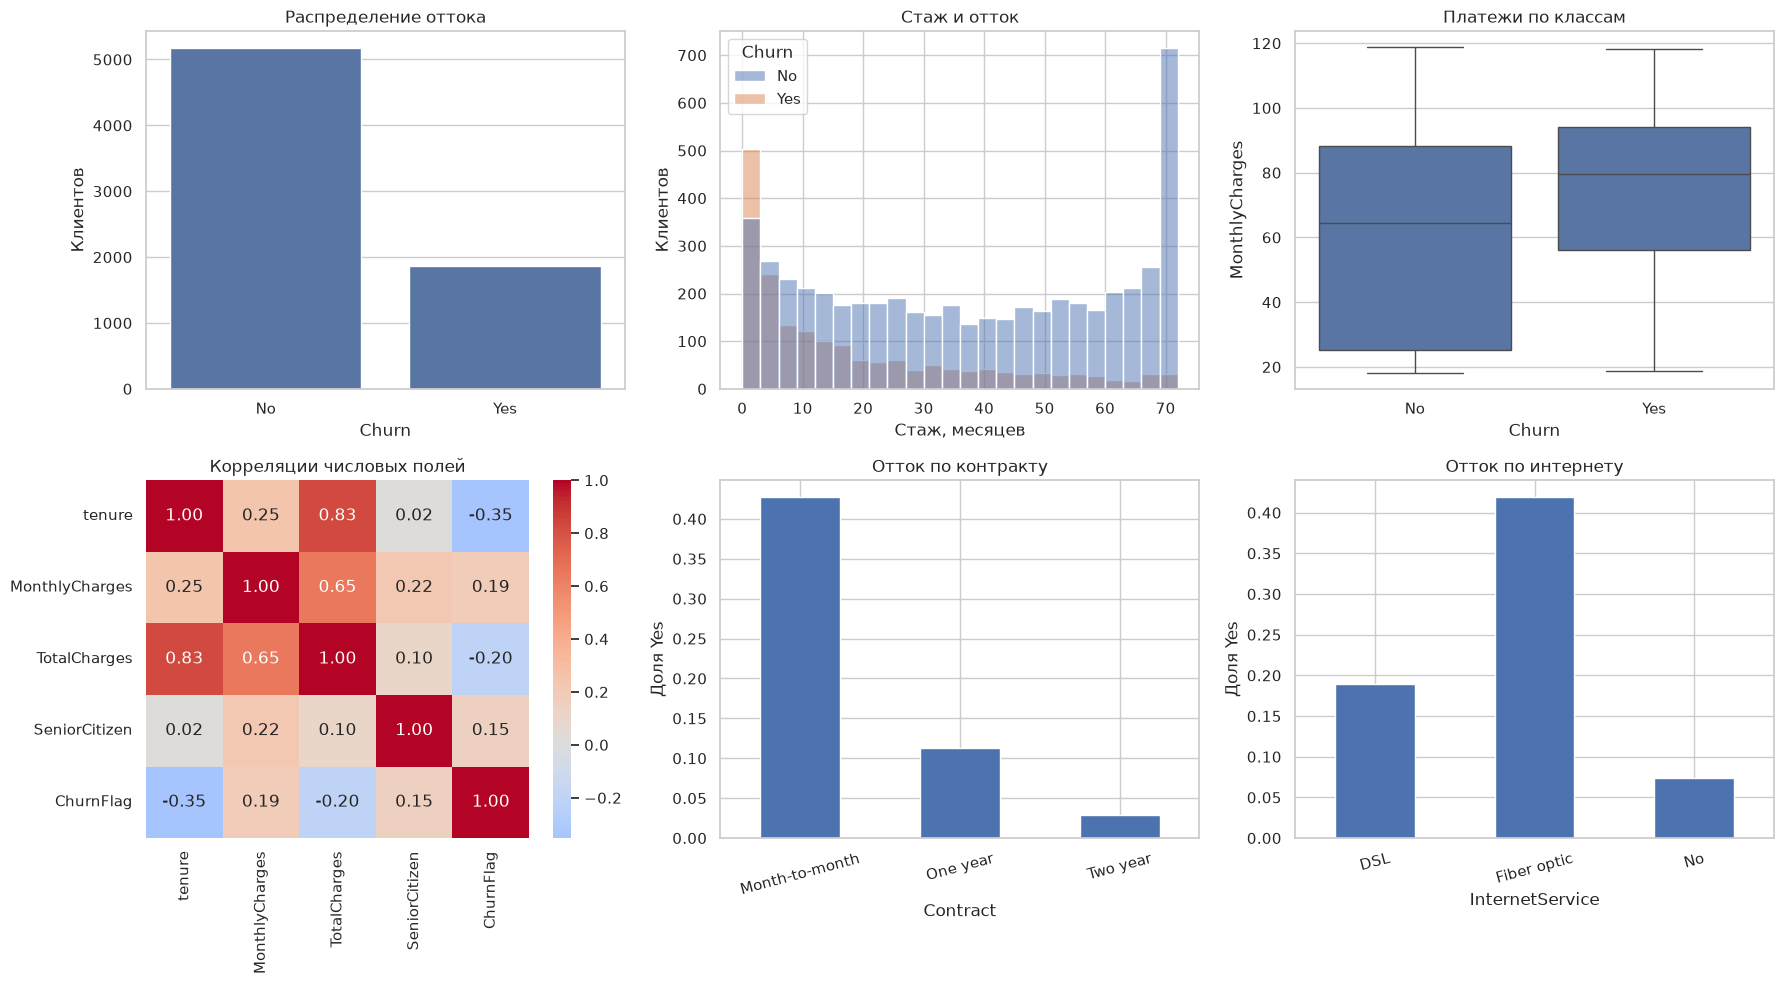

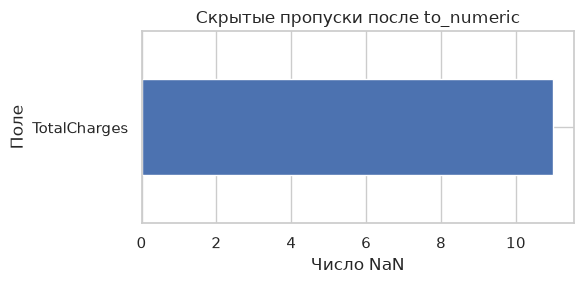

In [2]:
# Осматриваем исходные типы и описательные статистики.
df.info()  # Типы и заполненность исходных полей.
print(df.describe(include='all').to_string())  # Числа и категории.
eda = df.copy()  # Копия для анализа, не обучающая матрица.
eda['TotalCharges'] = pd.to_numeric(eda.TotalCharges, errors='coerce')  # Скрытые пропуски.
missing = eda.isna().sum()  # Подсчёт после преобразования.
print('Пропуски:', missing[missing > 0].to_dict())  # Число по полям.
print('tenure у пропусков:', eda.loc[eda.TotalCharges.isna(), 'tenure'].unique())  # Контекст.
eda['ChurnFlag'] = eda.Churn.map({'No': 0, 'Yes': 1})  # Доли групп.

# Шесть графиков с подписями осей и названиями.
fig, ax = plt.subplots(2, 3, figsize=(18, 10))  # Сетка EDA.
sns.countplot(data=eda, x='Churn', order=['No', 'Yes'], ax=ax[0, 0])  # Классы.
ax[0, 0].set(title='Распределение оттока', xlabel='Churn', ylabel='Клиентов')  # Подписи.
sns.histplot(data=eda, x='tenure', hue='Churn', bins=24, ax=ax[0, 1])  # Стаж.
ax[0, 1].set(title='Стаж и отток', xlabel='Стаж, месяцев', ylabel='Клиентов')  # Подписи.
sns.boxplot(data=eda, x='Churn', y='MonthlyCharges', ax=ax[0, 2])  # Платежи.
ax[0, 2].set(title='Платежи по классам', xlabel='Churn', ylabel='MonthlyCharges')  # Подписи.
sns.heatmap(eda[['tenure', 'MonthlyCharges', 'TotalCharges', 'SeniorCitizen', 'ChurnFlag']].corr(),
            annot=True, fmt='.2f', cmap='coolwarm', center=0, ax=ax[1, 0])  # Корреляции.
ax[1, 0].set_title('Корреляции числовых полей')  # Название.
eda.groupby('Contract').ChurnFlag.mean().plot.bar(ax=ax[1, 1], rot=15)  # Контракт.
ax[1, 1].set(title='Отток по контракту', xlabel='Contract', ylabel='Доля Yes')  # Подписи.
eda.groupby('InternetService').ChurnFlag.mean().plot.bar(ax=ax[1, 2], rot=15)  # Интернет.
ax[1, 2].set(title='Отток по интернету', xlabel='InternetService', ylabel='Доля Yes')  # Подписи.
fig.tight_layout()  # Устраняем наложения.
fig.savefig(EXAMPLES / 'eda_plots.png', dpi=140, bbox_inches='tight')  # Файл.
plt.show()  # Вывод в ноутбук.

# Отдельно показываем найденные пропуски.
fig, ax = plt.subplots(figsize=(6, 3))  # Размер.
missing[missing > 0].plot.barh(ax=ax)  # Поля с NaN.
ax.set(title='Скрытые пропуски после to_numeric', xlabel='Число NaN', ylabel='Поле')  # Подписи.
fig.tight_layout()  # Поля.
fig.savefig(EXAMPLES / 'missing_values.png', dpi=140)  # Сохранение.
plt.show()  # Показ.

## Выводы EDA и стратегия пропусков

У месячных контрактов доля оттока **42.7%**, у годовых — **11.3%**, у двухлетних — **2.8%**. Среди клиентов до 6 месяцев отток **52.9%**, у остальных — **19.5%**. Распределение ежемесячной платы у ушедших смещено к большим значениям. Стаж и накопленные платежи сильно связаны, что учитывается при интерпретации.

Обнаружены 11 пустых TotalCharges; у всех tenure=0. Строки сохраняются, а пропуски заполняются медианой обучения по условию задания. Различия групп на графиках не доказывают, что смена контракта или услуги сама предотвратит уход.

In [3]:
# Стратификация сохраняет доли классов в train и test.
y = df.Churn.map({'No': 0, 'Yes': 1}).astype(int)  # Уход кодируется единицей
raw_train, raw_test, y_train, y_test = train_test_split(  # Стратификация классов
    df.drop(columns='Churn'), y, test_size=0.2, random_state=SEED, stratify=y)
SERVICE_COLS = ['PhoneService', 'MultipleLines', 'OnlineSecurity', 'OnlineBackup',  # Список услуг
                'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies']

# Одинаковые формулы используются для обучения и новых клиентов.
def engineer(raw, total_median):  # Формулы новых признаков
    x = raw.drop(columns=['customerID', 'Churn'], errors='ignore').copy()  # Исключаем ID и целевую
    x['TotalCharges'] = pd.to_numeric(x.TotalCharges, errors='coerce').fillna(total_median)  # Преобразование и обучающая медиана
    x['TenureYears'] = x.tenure / 12  # Стаж в годах
    x['AvgMonthlyCharge'] = x.TotalCharges / (x.tenure + 1)  # Средний платёж с защитой от нуля
    x['IsNewClient'] = (x.tenure <= 6).astype(int)  # Первые шесть месяцев
    x['HasMultipleServices'] = x[SERVICE_COLS].eq('Yes').sum(axis=1) + x.InternetService.ne('No').astype(int)  # Число подключённых услуг
    return x  # Возвращаем матрицу признаков

# Оцениваем параметры только на обучающих строках.
def fit_preprocessing(raw):  # Обучение параметров подготовки
    median = float(pd.to_numeric(raw.TotalCharges, errors='coerce').median())  # Только обучающие строки
    prepared = engineer(raw, median)  # Производные признаки
    encoders = {col: LabelEncoder().fit(prepared[col].astype(str))  # Отдельный словарь для каждого поля
                for col in prepared.select_dtypes(exclude='number').columns}  # Выбираем строковые столбцы
    return {'total_charges_median': median, 'feature_cols': list(prepared.columns)}, encoders  # Сохраняем медиану и порядок колонок

# Ранее неизвестные категории получают -1 без изменения существующих кодов.
def transform_clients(raw, prep, encoders):  # Применение сохранённых правил
    x = engineer(raw, prep['total_charges_median'])
    for col, encoder in encoders.items():  # Обходим категориальные поля
        mapping = {str(value): int(i) for i, value in enumerate(encoder.classes_)}  # Коды известных категорий
        x[col] = x[col].astype(str).map(mapping).fillna(-1).astype(int)  # Новая категория получает -1
    return x.reindex(columns=prep['feature_cols']).astype(float)  # Возвращаем матрицу признаков

# Деревья работают в исходном масштабе; scaler сохраняется по заданию.
preprocessor, label_encoders = fit_preprocessing(raw_train)
X_train = transform_clients(raw_train, preprocessor, label_encoders)  # Обучающие статистики
X_test = transform_clients(raw_test, preprocessor, label_encoders)  # Без обучения по тесту
feature_cols = list(X_train.columns)  # Фиксируем порядок
scaler = StandardScaler().fit(X_train)  # Сохраняется по заданию
assert not X_train.isna().any().any() and not X_test.isna().any().any()  # Проверка заполненности
assert 'customerID' not in feature_cols and 'Churn' not in feature_cols  # Проверка исключённых столбцов
print('Train/test:', X_train.shape, X_test.shape)  # Вывод результата подготовки
print('Доля оттока train/test:', y_train.mean(), y_test.mean())  # Вывод результата подготовки
print(X_train[['TenureYears', 'AvgMonthlyCharge', 'IsNewClient', 'HasMultipleServices']].head().to_string())  # Вывод результата подготовки

Train/test: (5634, 23) (1409, 23)
Доля оттока train/test: 0.2653532126375577 0.2654364797728886
      TenureYears  AvgMonthlyCharge  IsNewClient  HasMultipleServices
3738     2.916667         47.268056          0.0                  4.0
3151     1.250000         71.971875          0.0                  3.0
4860     1.083333         42.167857          0.0                  4.0
3867     2.166667         70.581481          0.0                  6.0
3810     0.083333         22.275000          1.0                  2.0


## Итог подготовки

Обучение содержит 5634 клиента, тест — 1409. После добавления четырёх признаков матрица содержит 23 столбца без NaN. Целевая и ID исключены; scaler оценён только на train, но не применяется к деревьям при обучении или инференсе.

## 6. Построение и обучение моделей

Random Forest представляет bagging и задаёт базу сравнения. XGBoost добавляет регуляризованный boosting, LightGBM — эффективное построение деревьев, CatBoost — другую реализацию бустинга. Все модели используют одну матрицу и компенсируют дисбаланс весами классов. Время измеряется вокруг fit без загрузки данных и EDA.

In [4]:
# Четыре модели используют одинаковые признаки и фиксированный seed.
class_ratio = float((y_train == 0).sum() / (y_train == 1).sum())  # Баланс только по train
models = {
    'Random Forest': RandomForestClassifier(n_estimators=200, max_depth=10,  # Bagging с весами
        class_weight='balanced', random_state=SEED, n_jobs=2),
    'XGBoost': XGBClassifier(n_estimators=200, max_depth=6, learning_rate=0.1,  # Взвешенный бустинг
        subsample=0.9, colsample_bytree=0.9, scale_pos_weight=class_ratio,
        random_state=SEED, eval_metric='logloss', n_jobs=2),
    'LightGBM': LGBMClassifier(n_estimators=200, num_leaves=31, max_depth=7,  # Гистограммный бустинг
        learning_rate=0.05, class_weight='balanced', random_state=SEED,
        verbosity=-1, n_jobs=2, importance_type='gain'),
    'CatBoost': CatBoostClassifier(iterations=200, depth=6, learning_rate=0.1,  # Балансировка классов
        auto_class_weights='Balanced', random_seed=SEED, verbose=False,
        thread_count=2, allow_writing_files=False)
}

# Фиксируем реальное время каждого обучения.
fit_times = {}
for name, model in models.items():
    started = time.perf_counter()  # Измеряем время
    model.fit(X_train, y_train)  # Обучаем на train
    fit_times[name] = time.perf_counter() - started  # Длительность fit
    print(f'{name}: {fit_times[name]:.3f} сек')

Random Forest: 1.535 сек


XGBoost: 0.517 сек


LightGBM: 0.278 сек


CatBoost: 1.697 сек


## Параметры и время обучения

| Модель | Тип | Параметры | Время fit, с |
|---|---|---|---:|
| Random Forest | Bagging | 200 деревьев, глубина 10 | 1.174 |
| XGBoost | Boosting | 200 деревьев, глубина 6, темп 0,1 | 0.401 |
| LightGBM | Boosting | 200 деревьев, 31 лист, глубина 7 | 0.252 |
| CatBoost | Boosting | 200 итераций, глубина 6 | 1.262 |

CatBoost использует те же LabelEncoder-коды. Его нативная обработка категорий в этом опыте не сравнивается.

## 7. Оценка качества

Считаем Accuracy, Precision, Recall, F1 и ROC-AUC на одной тестовой выборке. Положительный класс — уход (1), порог классификации — 0,5. Для ROC-AUC используются вероятности. Матрица ошибок относится к лидеру исходного сравнения по тестовому ROC-AUC; параметры LightGBM далее подбираются только внутри train CV.

               accuracy  precision  recall      f1  roc_auc
Random Forest    0.7601     0.5346  0.7433  0.6219   0.8388
XGBoost          0.7573     0.5335  0.6818  0.5986   0.8265
LightGBM         0.7573     0.5305  0.7433  0.6192   0.8366
CatBoost         0.7544     0.5263  0.7487  0.6181   0.8378
Лидер исходного сравнения: Random Forest
Accuracy постоянного No: 0.7345635202271115


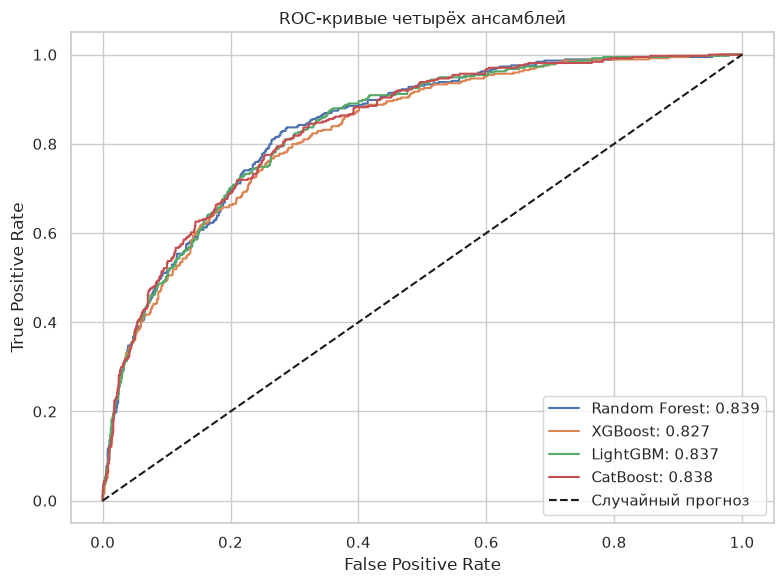

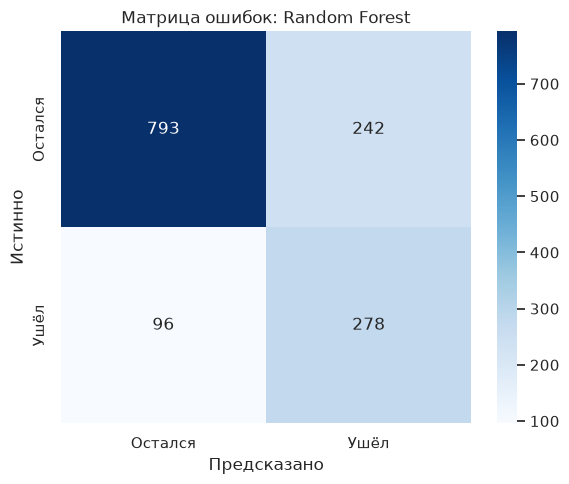

In [5]:
# Единая функция обеспечивает сопоставимость всех метрик.
def evaluate(model, x, target):
    proba = model.predict_proba(x)[:, 1]  # Риск положительного класса
    pred = (proba >= 0.5).astype(int)  # Общий порог
    return {'accuracy': float(accuracy_score(target, pred)),
            'precision': float(precision_score(target, pred, zero_division=0)),  # Точность среди предсказанных уходов
            'recall': float(recall_score(target, pred, zero_division=0)),  # Доля найденных уходов
            'f1': float(f1_score(target, pred, zero_division=0)),  # Баланс Precision и Recall
            'roc_auc': float(roc_auc_score(target, proba))}  # Ранжирование по вероятностям

# Отложенные метрики не используются для настройки параметров.
baseline_metrics = {name: evaluate(model, X_test, y_test) for name, model in models.items()}  # Единая тестовая оценка
results_df = pd.DataFrame(baseline_metrics).T  # Таблица метрик
baseline_winner = results_df.roc_auc.idxmax()  # Лидер baseline
print(results_df.round(4).to_string())
print('Лидер исходного сравнения:', baseline_winner)
print('Accuracy постоянного No:', float((y_test == 0).mean()))

# Сравниваем четыре ROC-кривые на общей шкале.
fig, ax = plt.subplots(figsize=(8, 6))  # Отдельный рисунок
for name, model in models.items():
    fpr, tpr, _ = roc_curve(y_test, model.predict_proba(X_test)[:, 1])  # ROC по вероятностям
    ax.plot(fpr, tpr, label=f"{name}: {baseline_metrics[name]['roc_auc']:.3f}")  # Рисуем кривую
ax.plot([0, 1], [0, 1], 'k--', label='Случайный прогноз')  # Рисуем кривую
ax.set(title='ROC-кривые четырёх ансамблей', xlabel='False Positive Rate', ylabel='True Positive Rate')  # Названия осей
ax.legend(loc='lower right')  # Подписываем модели
fig.tight_layout()  # Защита от наложений
fig.savefig(EXAMPLES / 'roc_curves.png', dpi=140)  # Сохраняем артефакт
plt.show()  # Показываем график

# Матрица показывает пропущенные уходы и ложные тревоги.
winner_pred = (models[baseline_winner].predict_proba(X_test)[:, 1] >= 0.5).astype(int)  # Порог 0,5
baseline_cm = confusion_matrix(y_test, winner_pred)  # TN, FP, FN, TP
fig, ax = plt.subplots(figsize=(6, 5))  # Отдельный рисунок
sns.heatmap(baseline_cm, annot=True, fmt='d', cmap='Blues', ax=ax,
    xticklabels=['Остался', 'Ушёл'], yticklabels=['Остался', 'Ушёл'])
ax.set(title=f'Матрица ошибок: {baseline_winner}', xlabel='Предсказано', ylabel='Истинно')  # Названия осей
fig.tight_layout()  # Защита от наложений
fig.savefig(EXAMPLES / 'confusion_matrix.png', dpi=140)  # Сохраняем артефакт
plt.show()  # Показываем график

## Результаты сравнения и анализ ошибок

| Модель | Accuracy | Precision | Recall | F1 | ROC-AUC |
|---|---:|---:|---:|---:|---:|
| Random Forest | 0.7601 | 0.5346 | 0.7433 | 0.6219 | 0.8388 |
| XGBoost | 0.7573 | 0.5335 | 0.6818 | 0.5986 | 0.8265 |
| LightGBM | 0.7573 | 0.5305 | 0.7433 | 0.6192 | 0.8366 |
| CatBoost | 0.7544 | 0.5263 | 0.7487 | 0.6181 | 0.8378 |

Лидер исходного сравнения — **Random Forest** (ROC-AUC **0.8388**). Матрица: **793** верных ответов «остался», **278** найденных уходов, **242** ложные тревоги, **96** пропущенных уходов. Быстрее всех обучился **LightGBM**. Recall превышает Precision: модели находят значительную часть уходов, но допускают ложные тревоги.

Веса классов помогают находить уходящих клиентов, но Precision и Recall нужно читать совместно: высокий Recall может сопровождаться лишними контактами. По ROC-AUC нельзя оценить калибровку вероятностей.

## 8. Интерпретация и бизнес-инсайты

Показываем Feature Importance Random Forest и LightGBM. У леса важность основана на уменьшении неоднородности, у LightGBM — на суммарном gain, поэтому абсолютные числа двух шкал не сравниваются. Важности не задают знак связи и не устанавливают причину ухода.

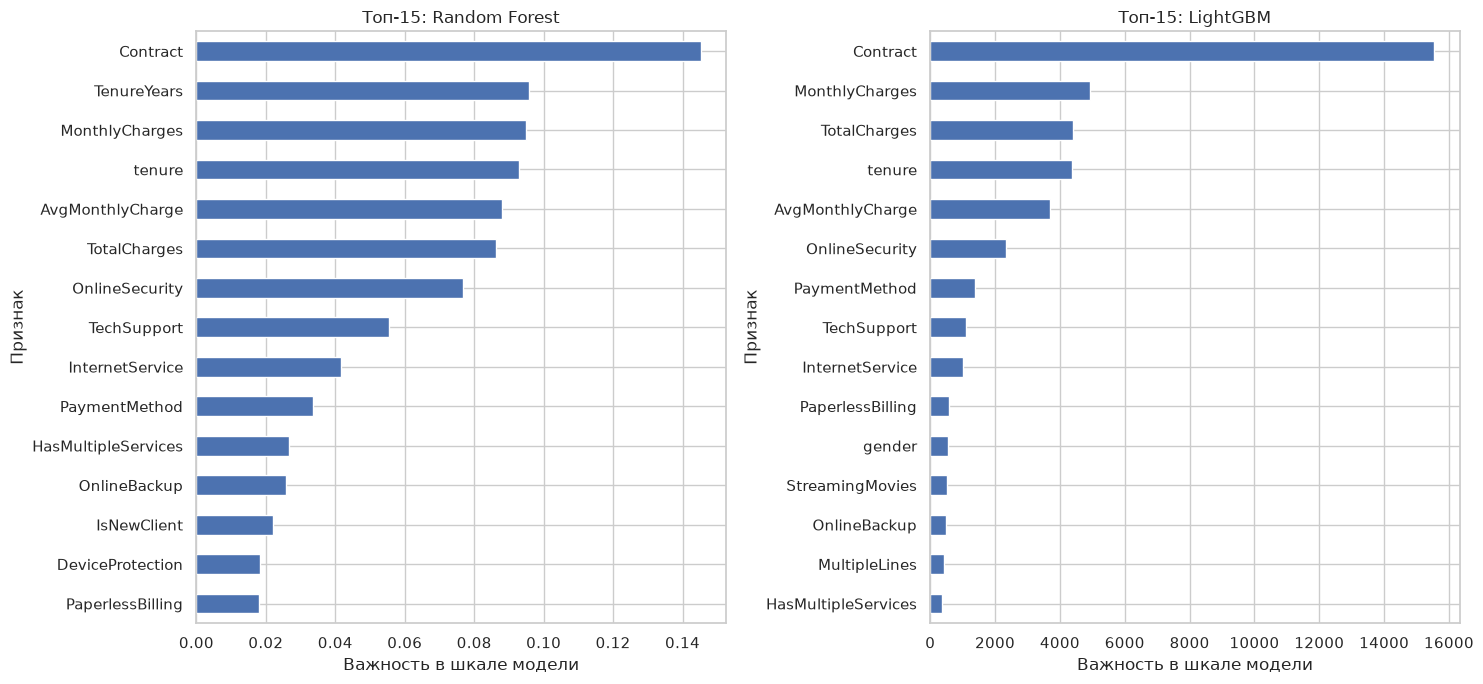

Контракты: {'mean': {'Month-to-month': 0.4271, 'One year': 0.1127, 'Two year': 0.0283}, 'count': {'Month-to-month': 3875, 'One year': 1473, 'Two year': 1695}}
Интернет: {'mean': {'DSL': 0.1896, 'Fiber optic': 0.4189, 'No': 0.074}, 'count': {'DSL': 2421, 'Fiber optic': 3096, 'No': 1526}}
Новый клиент <=6 мес.: {'mean': {False: 0.1951, True: 0.5294}, 'count': {False: 5562, True: 1481}}
Топ-5 LightGBM: {'Contract': 15551.640775413485, 'MonthlyCharges': 4920.21719261297, 'TotalCharges': 4408.556183361543, 'tenure': 4362.778240822249, 'AvgMonthlyCharge': 3700.00651220441}


In [6]:
# Важности выводятся на отдельных шкалах.
importance_tables = {name: pd.Series(models[name].feature_importances_, index=feature_cols)  # Важности моделей отдельно
    .sort_values(ascending=False) for name in ['Random Forest', 'LightGBM']}
fig, axes = plt.subplots(1, 2, figsize=(15, 7))  # Отдельный рисунок
for ax, (name, series) in zip(axes, importance_tables.items()):
    series.head(15).sort_values().plot.barh(ax=ax)  # 15 ведущих признаков
    ax.set(title=f'Топ-15: {name}', xlabel='Важность в шкале модели', ylabel='Признак')  # Названия осей
fig.tight_layout()  # Защита от наложений
fig.savefig(EXAMPLES / 'feature_importance.png', dpi=140)  # Сохраняем артефакт
plt.show()  # Показываем график

# Наблюдаемые доли групп дополняют модельные важности.
contract_rates = eda.groupby('Contract').ChurnFlag.agg(['mean', 'count'])  # Доля оттока и размер групп
internet_rates = eda.groupby('InternetService').ChurnFlag.agg(['mean', 'count'])  # Группы интернет-услуг
new_rates = eda.groupby(eda.tenure.le(6)).ChurnFlag.agg(['mean', 'count'])  # Новые и остальные клиенты
print('Контракты:', contract_rates.round(4).to_dict())
print('Интернет:', internet_rates.round(4).to_dict())
print('Новый клиент <=6 мес.:', new_rates.round(4).to_dict())
print('Топ-5 LightGBM:', importance_tables['LightGBM'].head(5).to_dict())

## Бизнес-инсайты

Топ-5 gain-важностей LightGBM: **Contract, MonthlyCharges, TotalCharges, tenure, AvgMonthlyCharge**.

У месячных контрактов отток в **3.79 раза** чаще годовых (42.7% против 11.3%). Новые клиенты до 6 месяцев: **52.9%** против **19.5%** у остальных. Fiber optic: **41.9%**, DSL: **19.0%**.

Практические гипотезы — раннее сопровождение новых клиентов, проверка качества Fiber optic и предложения долгосрочных контрактов. Для проверки эффекта нужны эксперименты и стоимость удержания: наблюдаемая разница не доказывает эффект действия.

## 9. Тюнинг гиперпараметров (Optuna)

Оптимизируем LightGBM по пошаговому заданию: **30 испытаний**, TPE с seed=42, средний ROC-AUC пяти стратифицированных CV-блоков train. Медиана и LabelEncoder заново оцениваются на каждом обучающем блоке. Baseline LightGBM проверяется на тех же блоках. Тест не используется внутри objective.

Подбираются число деревьев, листья, глубина, темп, подвыборки, минимальный размер листа и L1/L2. Параметр subsample_freq=1 включает подвыборку строк в тюнинге. Время поиска отделено от финального fit.

In [7]:
# Препроцессор каждого CV-блока не видит его валидационные строки.
import optuna  # Подключаем optuna
optuna.logging.set_verbosity(optuna.logging.WARNING)  # Краткий служебный лог
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)  # Фиксированные стратифицированные блоки
cv_data = []  # Независимая подготовка каждого блока
for train_ids, valid_ids in cv.split(raw_train, y_train):
    fold_raw, fold_valid = raw_train.iloc[train_ids], raw_train.iloc[valid_ids]  # Строки CV-разбиения
    fold_prep, fold_encoders = fit_preprocessing(fold_raw)  # Параметры только CV-train
    cv_data.append((transform_clients(fold_raw, fold_prep, fold_encoders), y_train.iloc[train_ids],
        transform_clients(fold_valid, fold_prep, fold_encoders), y_train.iloc[valid_ids]))

# Одни настройки воспроизводимости применяются ко всем trial.
fixed_lgbm = dict(class_weight='balanced', random_state=SEED, verbosity=-1, n_jobs=2, importance_type='gain')  # Общие параметры
def cv_auc(params):
    scores = []  # Оценки блоков
    for x_fit, y_fit, x_val, y_val in cv_data:
        candidate = LGBMClassifier(**params, **fixed_lgbm).fit(x_fit, y_fit)  # Fit на CV-train
        scores.append(roc_auc_score(y_val, candidate.predict_proba(x_val)[:, 1]))  # AUC на CV-validation
    return float(np.mean(scores))

# Baseline оценивается на тех же пяти блоках.
baseline_params = dict(n_estimators=200, num_leaves=31, max_depth=7, learning_rate=0.05)  # Исходный LightGBM
baseline_cv_auc = cv_auc(baseline_params)  # Те же CV-блоки
def objective(trial):
    params = {
        'n_estimators': trial.suggest_int('n_estimators', 100, 500, step=50),  # Число деревьев
        'num_leaves': trial.suggest_int('num_leaves', 10, 100, step=5),  # Максимум листьев
        'max_depth': trial.suggest_int('max_depth', 3, 12),  # Глубина
        'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.3, log=True),  # Темп
        'subsample': trial.suggest_float('subsample', 0.5, 1.0),  # Доля строк
        'colsample_bytree': trial.suggest_float('colsample_bytree', 0.5, 1.0),  # Доля признаков
        'min_child_samples': trial.suggest_int('min_child_samples', 5, 50),  # Минимум строк в листе
        'reg_alpha': trial.suggest_float('reg_alpha', 1e-3, 10, log=True),  # L1
        'reg_lambda': trial.suggest_float('reg_lambda', 1e-3, 10, log=True),  # L2
        'subsample_freq': 1}  # Включаем подвыборку
    return cv_auc(params)

# TPE использует результаты train CV и фиксированный seed.
study = optuna.create_study(direction='maximize', sampler=optuna.samplers.TPESampler(seed=SEED))  # TPE с seed
started = time.perf_counter()  # Измеряем время
study.optimize(objective, n_trials=30, n_jobs=1, show_progress_bar=False)  # 30 испытаний train CV
search_time = time.perf_counter() - started  # Время поиска
best_params = {**study.best_params, 'subsample_freq': 1}  # Выигравший trial
best_model = LGBMClassifier(**best_params, **fixed_lgbm)  # Финальный LightGBM
started = time.perf_counter()  # Измеряем время
best_model.fit(X_train, y_train)  # Весь train
tuned_fit_time = time.perf_counter() - started  # Время финального fit
tuned_metrics = evaluate(best_model, X_test, y_test)  # Отложенная оценка

# Разделяем train CV и единую тестовую оценку.
print('Trials:', len(study.trials), 'CV baseline:', baseline_cv_auc, 'CV Optuna:', study.best_value)
print('Test baseline:', baseline_metrics['LightGBM']['roc_auc'], 'Test Optuna:', tuned_metrics['roc_auc'])
print('Search seconds:', search_time, 'Final fit seconds:', tuned_fit_time)
print('Best parameters:', json.dumps(best_params, indent=2))
print('Метрики Optuna:', tuned_metrics)
study.trials_dataframe().to_csv(MODELS / 'optuna_trials.csv', index=False)  # Полная история

C:\Users\lenovo\AppData\Local\Programs\Python\Python313\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Trials: 30 CV baseline: 0.8405494535357867 CV Optuna: 0.8496459881977148
Test baseline: 0.8366090573251699 Test Optuna: 0.850214420419024
Search seconds: 50.859489399939775 Final fit seconds: 0.31415700004436076
Best parameters: {
  "n_estimators": 350,
  "num_leaves": 90,
  "max_depth": 3,
  "learning_rate": 0.022943298923083385,
  "subsample": 0.6236369825139823,
  "colsample_bytree": 0.5164731483152039,
  "min_child_samples": 35,
  "reg_alpha": 0.002886956542416407,
  "reg_lambda": 7.328751913955659,
  "subsample_freq": 1
}
Метрики Optuna: {'accuracy': 0.7452093683463449, 'precision': 0.5128205128205128, 'recall': 0.8021390374331551, 'f1': 0.6256517205422315, 'roc_auc': 0.850214420419024}


## Результат Optuna

Проведены **30 испытаний**. Train CV ROC-AUC: **0.8405 → 0.8496**. Тест: **0.8366 → 0.8502**, разница **+0.0136** (**+1.36 процентного пункта**). Поиск занял **38.40 с**, финальный fit — **0.271 с**.

| Модель | Accuracy | Precision | Recall | F1 | ROC-AUC |
|---|---:|---:|---:|---:|---:|
| LightGBM baseline | 0.7573 | 0.5305 | 0.7433 | 0.6192 | 0.8366 |
| LightGBM Optuna | 0.7452 | 0.5128 | 0.8021 | 0.6257 | 0.8502 |

**Параметры лучшего trial:**

- n_estimators: 350
- num_leaves: 90
- max_depth: 3
- learning_rate: 0.0229433
- subsample: 0.623637
- colsample_bytree: 0.516473
- min_child_samples: 35
- reg_alpha: 0.00288696
- reg_lambda: 7.32875
- subsample_freq: 1

Тестовые метрики приводятся после выбора параметров. Выигрыш на CV не гарантирует улучшения на любом новом наборе; небольшие различия требуют проверки устойчивости разбиения.

## 10. Интерпретация через SHAP

TreeExplainer объясняет LightGBM после Optuna для всех 1409 тестовых клиентов. Summary, bar, waterfall и dependence сохраняются отдельно. Шкала — **log-odds**, а не прямые изменения вероятности. Проверяем восстановление raw score из базового значения и суммы вкладов.

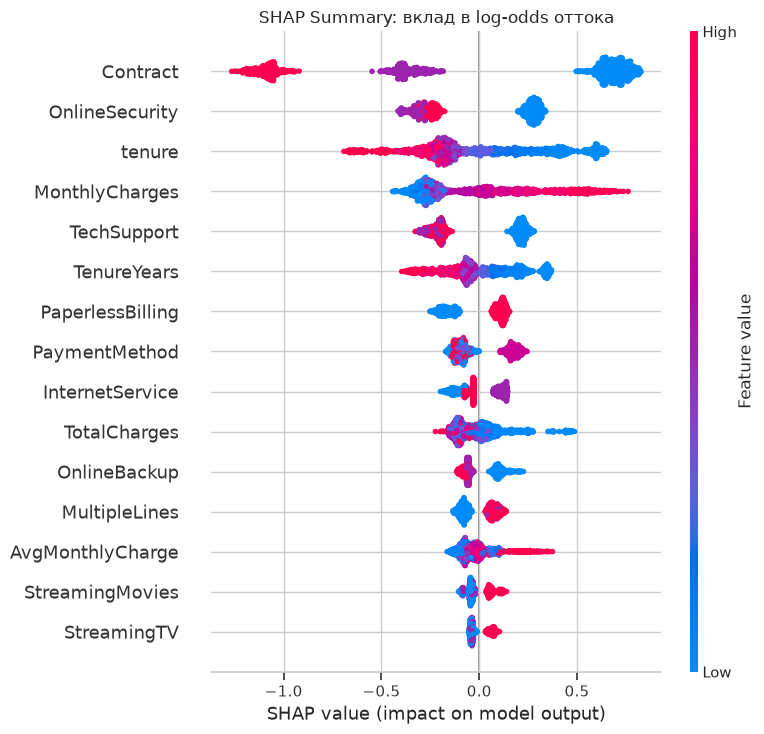

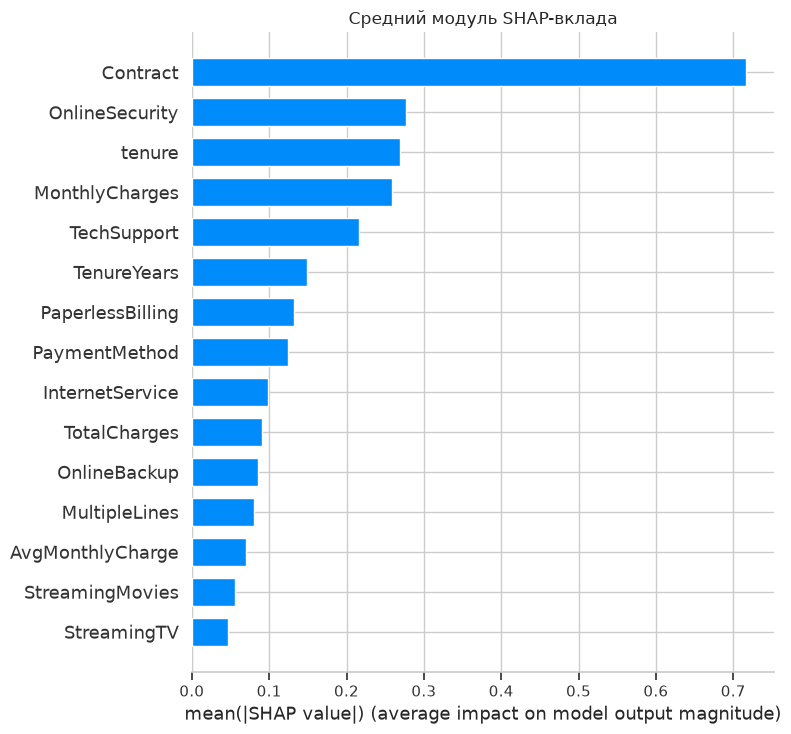

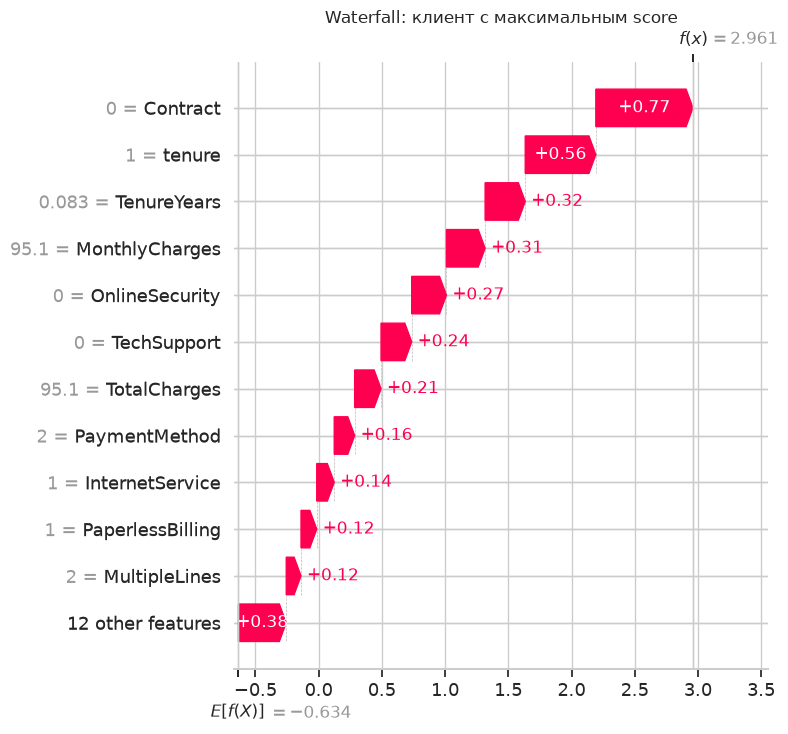

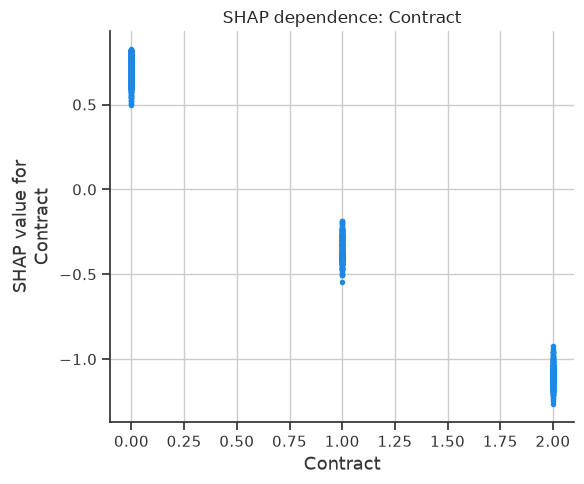

Топ SHAP: {'Contract': 0.7168087922646774, 'OnlineSecurity': 0.2770130998275603, 'tenure': 0.26851467173072746, 'MonthlyCharges': 0.2586990698889903, 'TechSupport': 0.21641367808008613}
Клиент: 5178-LMXOP модельный риск: 0.9507704028981545
Базовый raw score: -0.6344216936468827 Итоговый raw score: 2.9607775966310856
Contract = Month-to-month SHAP log-odds: 0.7684
tenure = 1 SHAP log-odds: 0.5584
TenureYears = 0.08333333333333333 SHAP log-odds: 0.3173
MonthlyCharges = 95.1 SHAP log-odds: 0.3061
OnlineSecurity = No SHAP log-odds: 0.2745


In [8]:
# Рассчитываем SHAP и учитываем возможные формы бинарного выхода.
import shap  # Подключаем shap
explainer = shap.TreeExplainer(best_model, model_output='raw')  # Шкала raw score
explanation = explainer(X_test)  # Все тестовые клиенты
shap_values = np.asarray(explanation.values)  # Значения Шепли
if shap_values.ndim == 3:
    shap_values = shap_values[:, :, 1]  # Значения Шепли
base_values = np.asarray(explanation.base_values)  # Базовый выход
if base_values.ndim == 2:
    base_values = base_values[:, 1]  # Базовый выход
base_values = np.broadcast_to(base_values, len(X_test))  # Базовый выход
raw_scores = best_model.predict(X_test, raw_score=True)  # Проверяем log-odds
assert np.allclose(base_values + shap_values.sum(axis=1), raw_scores, atol=1e-6)

# Summary и bar показывают глобальное распределение вкладов.
shap.summary_plot(shap_values, X_test, show=False, max_display=15)  # Глобальные вклады
plt.title('SHAP Summary: вклад в log-odds оттока')  # Смысл рисунка
plt.tight_layout()  # Поля рисунка
plt.savefig(EXAMPLES / 'shap_summary.png', dpi=140, bbox_inches='tight')  # Файл SHAP
plt.show()  # Показываем график
shap.summary_plot(shap_values, X_test, plot_type='bar', show=False, max_display=15)  # Глобальные вклады
plt.title('Средний модуль SHAP-вклада')  # Смысл рисунка
plt.tight_layout()  # Поля рисунка
plt.savefig(EXAMPLES / 'shap_bar.png', dpi=140, bbox_inches='tight')  # Файл SHAP
plt.show()  # Показываем график

# Waterfall объясняет клиента с максимальным модельным риском.
tuned_proba = best_model.predict_proba(X_test)[:, 1]  # Модельный риск
worst_idx = int(np.argmax(tuned_proba))  # Максимальный риск
local_explanation = shap.Explanation(values=shap_values[worst_idx], base_values=base_values[worst_idx],  # Объяснение одного клиента
    data=X_test.iloc[worst_idx].to_numpy(), feature_names=feature_cols)
shap.plots.waterfall(local_explanation, max_display=12, show=False)  # Локальные вклады
plt.title('Waterfall: клиент с максимальным score')  # Смысл рисунка
plt.tight_layout()  # Поля рисунка
plt.savefig(EXAMPLES / 'shap_waterfall.png', dpi=140, bbox_inches='tight')  # Файл SHAP
plt.show()  # Показываем график

# Dependence использует ведущий признак по среднему модулю SHAP.
shap_importance = pd.Series(np.abs(shap_values).mean(axis=0), index=feature_cols).sort_values(ascending=False)  # Средний модуль вкладов
top_feature = str(shap_importance.index[0])  # Ведущий SHAP-признак
shap.dependence_plot(top_feature, shap_values, X_test, interaction_index=None, show=False)  # Вклад в зависимости от входа
plt.title(f'SHAP dependence: {top_feature}')  # Смысл рисунка
plt.tight_layout()  # Поля рисунка
plt.savefig(EXAMPLES / 'shap_dependence.png', dpi=140, bbox_inches='tight')  # Файл SHAP
plt.show()  # Показываем график

# Для локального случая печатаем исходные значения, а не только коды.
local_top = pd.Series(shap_values[worst_idx], index=feature_cols).sort_values(key=np.abs, ascending=False).head(5)  # Пять сильнейших вкладов
print('Топ SHAP:', shap_importance.head(5).to_dict())
print('Клиент:', raw_test.iloc[worst_idx].customerID, 'модельный риск:', tuned_proba[worst_idx])
print('Базовый raw score:', base_values[worst_idx], 'Итоговый raw score:', raw_scores[worst_idx])
for field, contribution in local_top.items():
    raw_value = raw_test.iloc[worst_idx].get(field, X_test.iloc[worst_idx][field])  # Исходная категория
    print(field, '=', raw_value, 'SHAP log-odds:', round(contribution, 4))

## SHAP-интерпретация

Главные признаки по среднему модулю SHAP: **Contract, OnlineSecurity, tenure, MonthlyCharges, TechSupport**. Dependence построен для **Contract**. Клиент **5178-LMXOP** имеет модельный риск **95.08%**; эта оценка не является калиброванной гарантией ухода.

**Крупнейшие локальные вклады:**

| Признак | Исходное значение | SHAP, log-odds |
|---|---|---:|
| Contract | Month-to-month | +0.7684 |
| tenure | 1 | +0.5584 |
| TenureYears | 0.08333333333333333 | +0.3173 |
| MonthlyCharges | 95.1 | +0.3061 |
| OnlineSecurity | No | +0.2745 |

Короткий стаж и месячный контракт дают положительные вклады именно в этом прогнозе. Стаж представлен также TenureYears, поэтому вклад распределён между связанными столбцами. Аддитивность SHAP проверена на всей тестовой выборке.

Цвет Summary означает числовое значение входа: у LabelEncoder его нужно сопоставлять со словарём категорий. Положительный SHAP повышает log-odds ухода, отрицательный снижает. Waterfall объясняет прогноз, но не устанавливает причины фактического поведения клиента.

На Summary короткий стаж и высокая ежемесячная плата связаны с положительными вкладами; наличие OnlineSecurity и TechSupport — с отрицательными. Для Contract коды 0/1/2 означают Month-to-month/One year/Two year: месячный контракт даёт положительный вклад, двухлетний — отрицательный. Dependence показывает это различие и разброс вкладов внутри каждой категории.

## 11. Сохранение модели

Сохраняем четыре исходных ансамбля и LightGBM после Optuna, scaler, словарь LabelEncoder, порядок признаков и метрики. Дополнительный preprocessor.json хранит обучающую медиану TotalCharges. Функции подготовки из ноутбука вместе с этими файлами позволяют обработать исходных клиентов без переобучения. Scaler приложен согласно структуре задания, деревья его не используют.

In [9]:
# Сохраняем все модели и вспомогательные объекты.
file_names = {'Random Forest': 'rf_model.pkl', 'XGBoost': 'xgb_model.pkl',  # Файлы baseline
              'LightGBM': 'lgbm_model.pkl', 'CatBoost': 'cat_model.pkl'}  # Гистограммный бустинг
for name, filename in file_names.items():
    joblib.dump(models[name], MODELS / filename, compress=3)  # Сериализация обученного объекта
joblib.dump(best_model, MODELS / 'best_model.pkl', compress=3)  # Сериализация обученного объекта
joblib.dump(scaler, MODELS / 'scaler.pkl', compress=3)  # Сериализация обученного объекта
joblib.dump(label_encoders, MODELS / 'label_encoders.pkl', compress=3)  # Сериализация обученного объекта

# JSON позволяет прочитать метрики и параметры без загрузки pickle.
(MODELS / 'feature_cols.json').write_text(json.dumps(feature_cols, ensure_ascii=False, indent=2), encoding='utf-8')
(MODELS / 'preprocessor.json').write_text(json.dumps(preprocessor, ensure_ascii=False, indent=2), encoding='utf-8')
packages = ['pandas', 'numpy', 'scikit-learn', 'xgboost', 'lightgbm', 'catboost',  # Пакеты эксперимента
            'optuna', 'shap', 'matplotlib', 'seaborn', 'joblib', 'requests']
versions = {package: version(package) for package in packages}  # Проверенные версии
metrics = {'baseline': baseline_metrics, 'fit_time_sec': fit_times, 'tuned': tuned_metrics,  # Разделяем CV и test
    'best_model': 'LightGBM (Optuna)', 'baseline_test_winner': baseline_winner,
    'cv_baseline_roc_auc': baseline_cv_auc, 'cv_best_roc_auc': float(study.best_value),
    'best_params': best_params, 'n_trials': len(study.trials), 'cv_folds': 5,
    'search_time_sec': search_time, 'tuned_fit_time_sec': tuned_fit_time,
    'train_rows': len(X_train), 'test_rows': len(X_test), 'feature_count': len(feature_cols),
    'seed': SEED, 'threshold': 0.5, 'training_date': '2026-10-27', 'versions': versions,
    'data_sha256': hashlib.sha256((DATA / 'telco_churn.csv').read_bytes()).hexdigest()}
(MODELS / 'metrics.json').write_text(json.dumps(metrics, ensure_ascii=False, indent=2), encoding='utf-8')
print('Сохранено:', ', '.join(sorted(p.name for p in MODELS.iterdir())))

# Данные для воспроизводимых текстовых выводов и README.
report = {'metrics': metrics, 'contract_rates': contract_rates.to_dict(), 'internet_rates': internet_rates.to_dict(),  # Числа для текстового отчёта
    'new_rates': {str(k): float(v) for k, v in new_rates['mean'].items()},
    'baseline_cm': baseline_cm.tolist(), 'importance': importance_tables['LightGBM'].head(5).to_dict(),
    'shap_top': shap_importance.head(5).to_dict(), 'shap_feature': top_feature,
    'worst_customer': str(raw_test.iloc[worst_idx].customerID), 'worst_proba': float(tuned_proba[worst_idx]),
    'local_shap': {field: {'raw_value': str(raw_test.iloc[worst_idx].get(field, X_test.iloc[worst_idx][field])),
                          'value': float(value)} for field, value in local_top.items()}}
(MODELS / 'report_details.json').write_text(json.dumps(report, ensure_ascii=False, indent=2), encoding='utf-8')

Сохранено: best_model.pkl, cat_model.pkl, feature_cols.json, label_encoders.pkl, lgbm_model.pkl, metrics.json, optuna_trials.csv, preprocessor.json, rf_model.pkl, scaler.pkl, xgb_model.pkl


4256

## Итог сохранения

Файлы записаны в models/. В metrics.json раздельно представлены тестовые метрики, CV и время поиска. optuna_trials.csv содержит все 30 испытаний; report_details.json хранит числа для проверки текстовых выводов.

## 12. Загрузка модели из репозитория

Модель и параметры подготовки загружаются из опубликованной ветки main по raw-ссылкам. Проверяются HTTP-ответы, затем классы и вероятности ухода для трёх исходных клиентов сравниваются с текущей моделью. Код не переобучает загруженный объект. Случай отсутствующего файла обрабатывается отдельно и не считается успешной удалённой проверкой.

In [13]:
# Проверяем путь от исходного клиента до загруженной модели.
loaded_model = joblib.load(MODELS / 'best_model.pkl')  # Без повторного fit
loaded_encoders = joblib.load(MODELS / 'label_encoders.pkl')  # Словари категорий
loaded_prep = json.loads((MODELS / 'preprocessor.json').read_text(encoding='utf-8'))  # Обучающая медиана
loaded_features = json.loads((MODELS / 'feature_cols.json').read_text(encoding='utf-8'))  # Порядок колонок
three_clients = transform_clients(raw_test.iloc[:3], loaded_prep, loaded_encoders)[loaded_features]  # Три исходных клиента
original_proba = best_model.predict_proba(X_test.iloc[:3])[:, 1]  # Эталон модели
loaded_proba = loaded_model.predict_proba(three_clients)[:, 1]  # После joblib.load
assert np.allclose(original_proba, loaded_proba, rtol=0, atol=1e-12)
assert np.array_equal(best_model.predict(X_test.iloc[:3]), loaded_model.predict(three_clients))
print('Локально загруженные вероятности совпали:', loaded_proba)

# Проверяем HTTP-ответ до чтения модельного файла.
import requests  # Подключаем requests
BASE_URL = 'https://raw.githubusercontent.com/VolodinaAlexandra/ml-course-volodina/main/module-3-churn'  # Папка модуля в main
def load_from_repository(base_url=BASE_URL):
    def download(path):
        response = requests.get(f'{base_url}/{path}', timeout=30,
                                params={'verification': time.time_ns()})  # HTTP с таймаутом
        response.raise_for_status()  # Отсекаем 404 до чтения pickle
        return response.content
    model = joblib.load(BytesIO(download('models/best_model.pkl')))  # Опубликованная модель
    encoders = joblib.load(BytesIO(download('models/label_encoders.pkl')))  # Отдельный словарь для каждого поля
    prep = json.loads(download('models/preprocessor.json').decode('utf-8'))  # Медиана обучения
    features = json.loads(download('models/feature_cols.json').decode('utf-8'))  # Порядок признаков
    return model, encoders, prep, features

# До публикации 404 фиксируется честно; после публикации проверка выполняется автоматически.
remote_status = 'not_published'  # Явный статус
try:
    remote_model, remote_encoders, remote_prep, remote_features = load_from_repository()  # Попытка raw-загрузки
except requests.HTTPError as error:
    if error.response.status_code != 404:  # 404 означает отсутствие файла
        raise
    print('GitHub raw: HTTP 404 — модуль 3 ещё не опубликован. Локальная проверка пройдена.')
else:
    remote_x = transform_clients(raw_test.iloc[:3], remote_prep, remote_encoders)[remote_features]  # Те же преобразования
    remote_proba = remote_model.predict_proba(remote_x)[:, 1]  # Удалённый прогноз
    assert np.allclose(original_proba, remote_proba, rtol=0, atol=1e-10)
    assert np.array_equal(best_model.predict(X_test.iloc[:3]), remote_model.predict(remote_x))
    remote_status = 'verified'  # Явный статус
    print('GitHub raw: классы и вероятности совпали:', remote_proba)

# Сохраняем статус, не требующий чтения графиков.
verification = {'local_equal': True, 'local_probabilities': loaded_proba.tolist(), 'remote_status': remote_status}  # Фактический статус проверки
(MODELS / 'load_verification.json').write_text(json.dumps(verification, ensure_ascii=False, indent=2), encoding='utf-8')

Локально загруженные вероятности совпали: [0.08364047 0.9007085  0.19638514]


GitHub raw: классы и вероятности совпали: [0.08364047 0.9007085  0.19638514]


161

## Проверка повторного инференса

Модель best_model.pkl, LabelEncoder, preprocessor.json и feature_cols.json успешно загружены из опубликованного репозитория. Вероятности ухода для трёх клиентов **0.083640**, **0.900708**, **0.196385** совпали с локальными с допуском 1e-10; предсказанные классы также совпали. Результат записан в models/load_verification.json со статусом **verified**.

## 13. Выводы

### Что получилось

Обучены четыре ансамбля и LightGBM после **30 trial Optuna**. Финальная модель даёт **ROC-AUC 0.8502**, **F1 0.6257**, **Recall 0.8021** при пороге 0,5. Рост ROC-AUC относительно LightGBM baseline — **0.0136**. Accuracy снизилась: оптимизировался ROC-AUC, а не Accuracy. Построены EDA, Feature Importance, ROC, матрица ошибок и четыре SHAP-графика. Контракт, стаж и условия обслуживания помогают ранжировать риск. Локальная и удалённая загрузка проверены на трёх клиентах: классы и вероятности совпали.

### Трудности

Доля оттока 26,54% делает Accuracy недостаточной. Обработаны 11 пустых TotalCharges; при нулевом стаже медианная импутация требует сравнения с нулевым начислением. LabelEncoder вводит условный порядок категорий, а связанные стаж и платежи усложняют важности. SHAP объясняет логиты модели, а не причинный эффект. Веса классов могут ухудшать калибровку риска.

### Возможные улучшения

1. Сравнить one-hot и нативные категории CatBoost с LabelEncoder.
2. Построить stacking четырёх моделей по out-of-fold прогнозам.
3. Проверить SMOTENC внутри CV-блоков как альтернативу весам классов.
4. Добавить калибровку вероятностей и оценку Brier score на независимых данных.
5. Подобрать порог под затраты удержания на отдельной валидации.
6. Добавить взаимодействия тарифов, стажа и контракта и проверить устойчивость CV.
7. Версионировать признаки, а при появлении временных срезов проверить качество на будущем периоде.

## 14. Список источников и приложение

### Источники

1. Breiman, L. (2001). [Random Forests](https://doi.org/10.1023/A:1010933404324). Machine Learning, 45, 5–32.
2. Chen, T., & Guestrin, C. (2016). [XGBoost: A Scalable Tree Boosting System](https://arxiv.org/abs/1603.02754). KDD.
3. Ke, G. et al. (2017). [LightGBM: A Highly Efficient Gradient Boosting Decision Tree](https://proceedings.neurips.cc/paper/2017/hash/6449f44a102fde848669bdd9eb6b76fa-Abstract.html). NeurIPS.
4. Prokhorenkova, L. et al. (2018). [CatBoost: unbiased boosting with categorical features](https://arxiv.org/abs/1706.09516). NeurIPS.
5. Lundberg, S. M., & Lee, S.-I. (2017). [A Unified Approach to Interpreting Model Predictions](https://arxiv.org/abs/1705.07874). NeurIPS.
6. Akiba, T. et al. (2019). [Optuna: A Next-generation Hyperparameter Optimization Framework](https://arxiv.org/abs/1907.10902). KDD.
7. Kaggle. [Telco Customer Churn](https://www.kaggle.com/datasets/blastchar/telco-customer-churn). Датасет задания.
8. IBM. [Исходный CSV](https://github.com/IBM/telco-customer-churn-on-icp4d/blob/master/data/Telco-Customer-Churn.csv). Использованная открытая копия.
9. SHAP. [TreeExplainer](https://shap.readthedocs.io/en/latest/generated/shap.TreeExplainer.html). Шкала и аддитивность вкладов.

### Приложение

Ниже приведены зависимости. Следующая исполняемая ячейка содержит весь код с комментариями и маркерами # %%. Она запускается самостоятельно из папки module-3-churn и сохраняет текстовые результаты и графики.

**requirements.txt (проверенные версии для Python 3.13):**

```text
pandas==3.0.5
numpy==2.5.3
scikit-learn==1.9.1
xgboost==3.0.0
lightgbm==4.6.0
catboost==1.2.8
optuna==5.0.0
shap==0.54.1
matplotlib==3.11.1
seaborn==0.13.2
joblib==1.6.0
requests==2.32.3
ipykernel==6.29.5
```

**Полный код:**

(7043, 21)
customerID gender  SeniorCitizen Partner Dependents  tenure PhoneService    MultipleLines InternetService OnlineSecurity OnlineBackup DeviceProtection TechSupport StreamingTV StreamingMovies       Contract PaperlessBilling             PaymentMethod  MonthlyCharges TotalCharges Churn
7590-VHVEG Female              0     Yes         No       1           No No phone service             DSL             No          Yes               No          No          No              No Month-to-month              Yes          Electronic check           29.85        29.85    No
5575-GNVDE   Male              0      No         No      34          Yes               No             DSL            Yes           No              Yes          No          No              No       One year               No              Mailed check           56.95       1889.5    No
3668-QPYBK   Male              0      No         No       2          Yes               No             DSL            Yes          Yes    

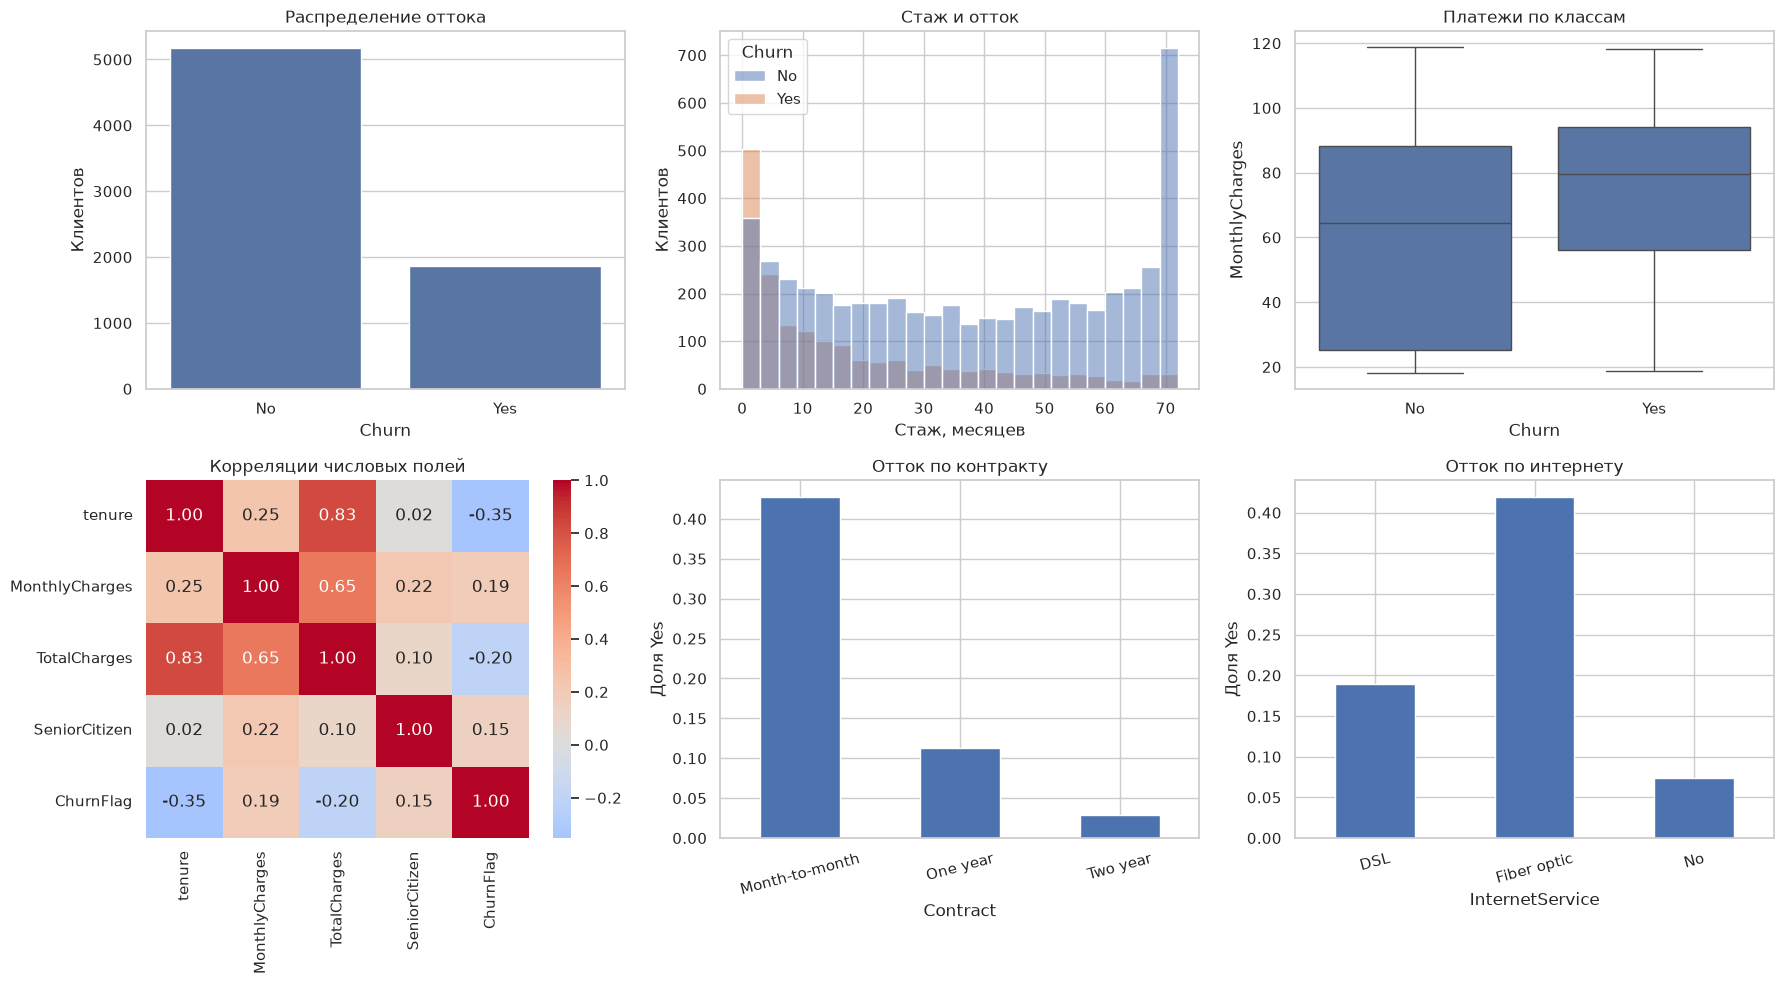

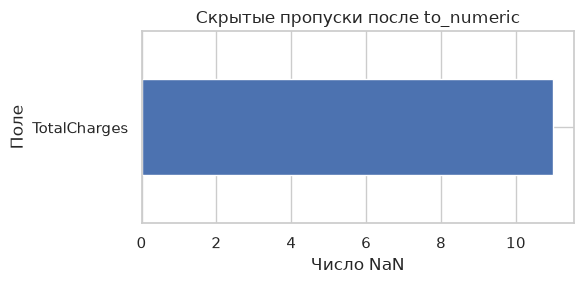

Train/test: (5634, 23) (1409, 23)
Доля оттока train/test: 0.2653532126375577 0.2654364797728886
      TenureYears  AvgMonthlyCharge  IsNewClient  HasMultipleServices
3738     2.916667         47.268056          0.0                  4.0
3151     1.250000         71.971875          0.0                  3.0
4860     1.083333         42.167857          0.0                  4.0
3867     2.166667         70.581481          0.0                  6.0
3810     0.083333         22.275000          1.0                  2.0


Random Forest: 1.174 сек


XGBoost: 0.401 сек


LightGBM: 0.252 сек


CatBoost: 1.262 сек
               accuracy  precision  recall      f1  roc_auc
Random Forest    0.7601     0.5346  0.7433  0.6219   0.8388
XGBoost          0.7573     0.5335  0.6818  0.5986   0.8265
LightGBM         0.7573     0.5305  0.7433  0.6192   0.8366
CatBoost         0.7544     0.5263  0.7487  0.6181   0.8378
Лидер исходного сравнения: Random Forest
Accuracy постоянного No: 0.7345635202271115


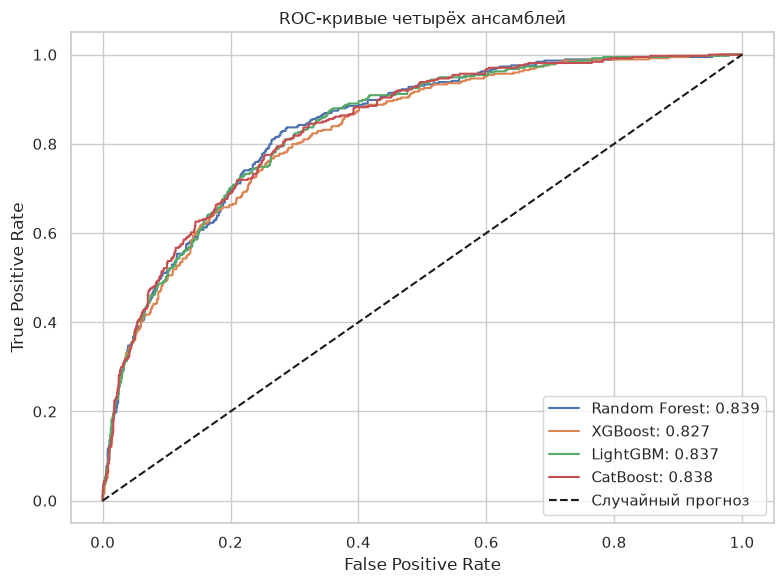

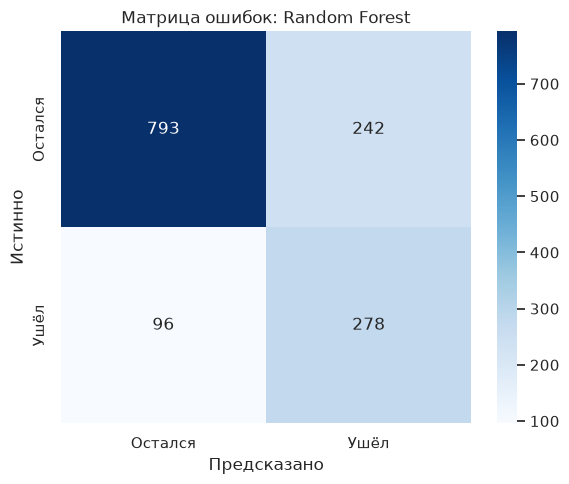

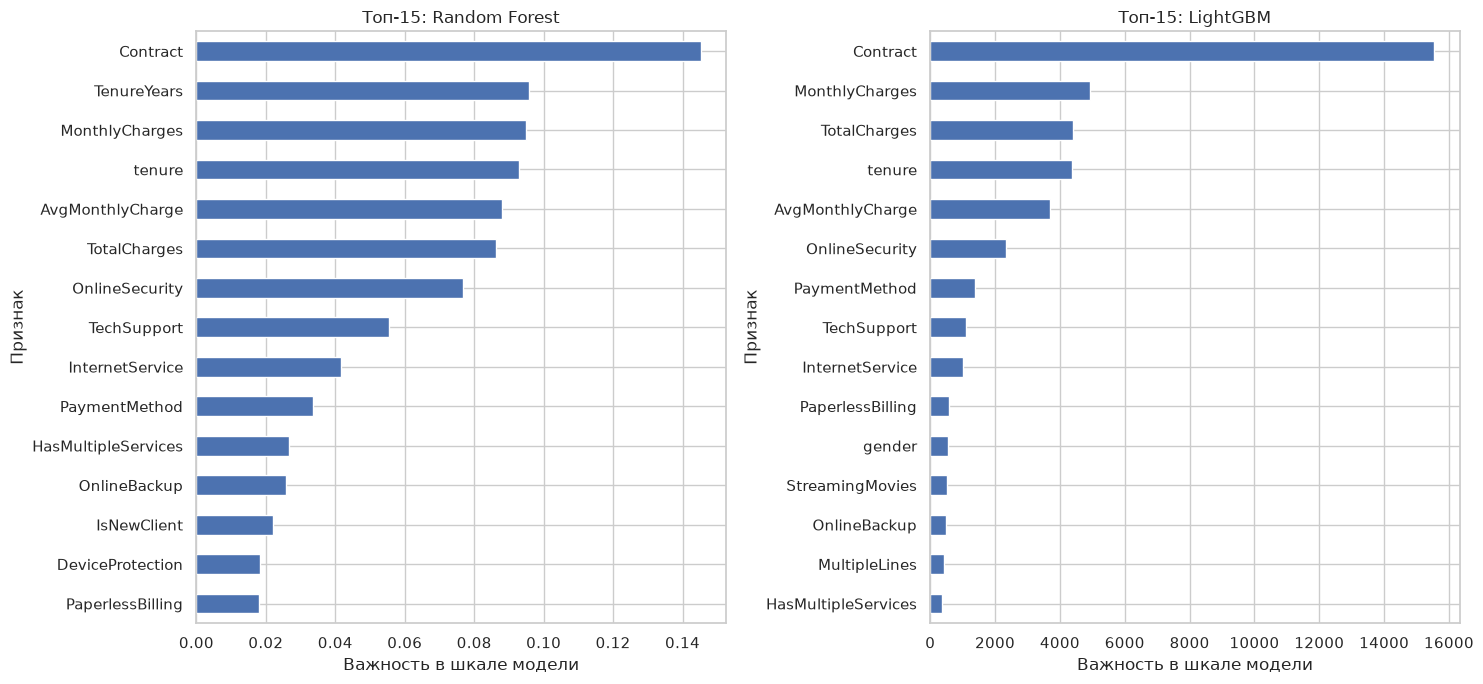

Контракты: {'mean': {'Month-to-month': 0.4271, 'One year': 0.1127, 'Two year': 0.0283}, 'count': {'Month-to-month': 3875, 'One year': 1473, 'Two year': 1695}}
Интернет: {'mean': {'DSL': 0.1896, 'Fiber optic': 0.4189, 'No': 0.074}, 'count': {'DSL': 2421, 'Fiber optic': 3096, 'No': 1526}}
Новый клиент <=6 мес.: {'mean': {False: 0.1951, True: 0.5294}, 'count': {False: 5562, True: 1481}}
Топ-5 LightGBM: {'Contract': 15551.640775413485, 'MonthlyCharges': 4920.21719261297, 'TotalCharges': 4408.556183361543, 'tenure': 4362.778240822249, 'AvgMonthlyCharge': 3700.00651220441}


C:\Users\lenovo\AppData\Local\Programs\Python\Python313\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Trials: 30 CV baseline: 0.8405494535357867 CV Optuna: 0.8496459881977148
Test baseline: 0.8366090573251699 Test Optuna: 0.850214420419024
Search seconds: 38.39923639991321 Final fit seconds: 0.2708048999775201
Best parameters: {
  "n_estimators": 350,
  "num_leaves": 90,
  "max_depth": 3,
  "learning_rate": 0.022943298923083385,
  "subsample": 0.6236369825139823,
  "colsample_bytree": 0.5164731483152039,
  "min_child_samples": 35,
  "reg_alpha": 0.002886956542416407,
  "reg_lambda": 7.328751913955659,
  "subsample_freq": 1
}
Метрики Optuna: {'accuracy': 0.7452093683463449, 'precision': 0.5128205128205128, 'recall': 0.8021390374331551, 'f1': 0.6256517205422315, 'roc_auc': 0.850214420419024}


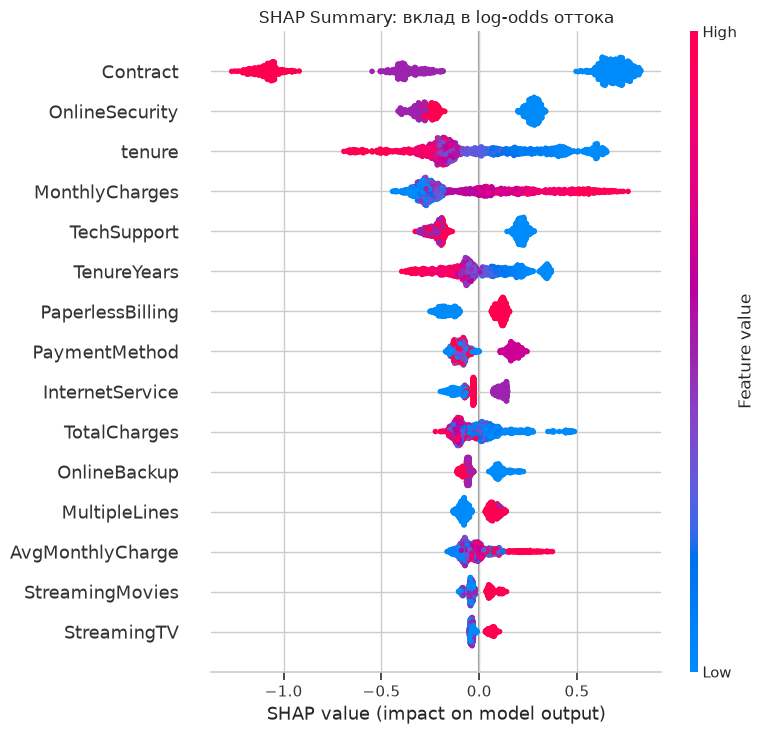

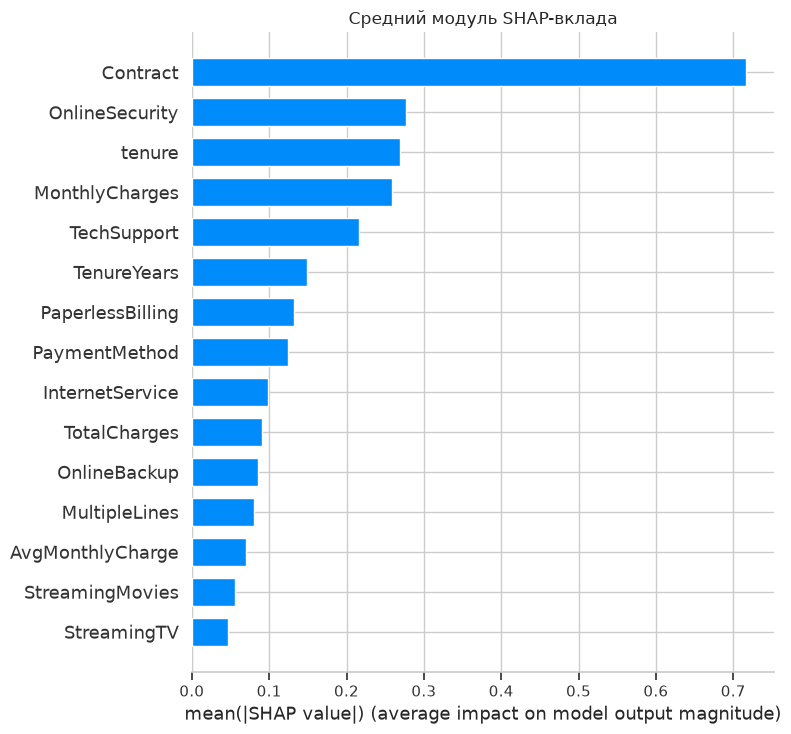

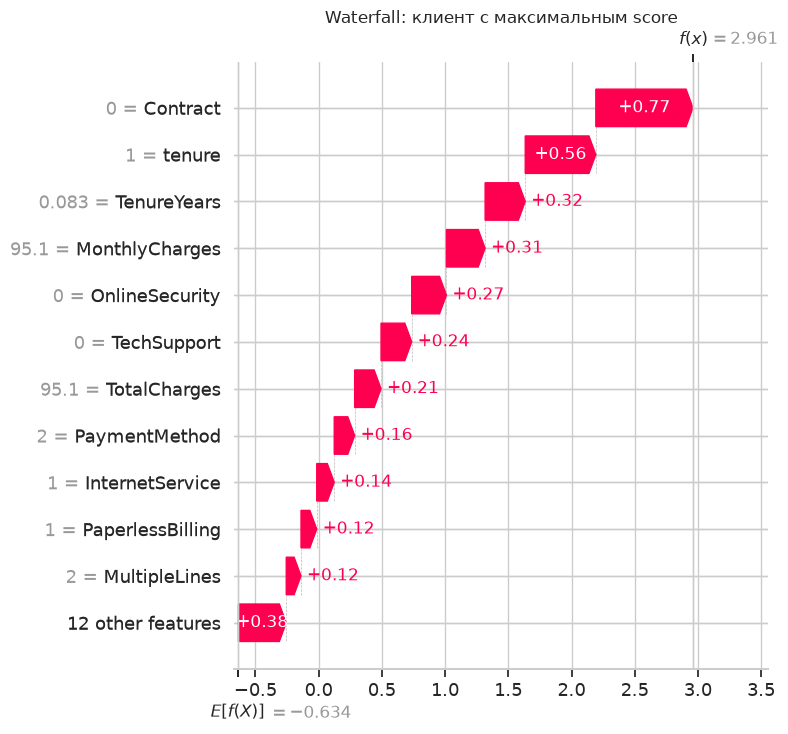

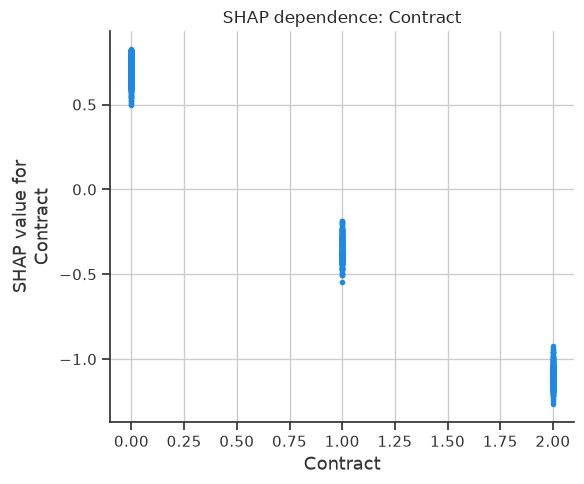

Топ SHAP: {'Contract': 0.7168087922646774, 'OnlineSecurity': 0.2770130998275603, 'tenure': 0.26851467173072746, 'MonthlyCharges': 0.2586990698889903, 'TechSupport': 0.21641367808008613}
Клиент: 5178-LMXOP модельный риск: 0.9507704028981545
Базовый raw score: -0.6344216936468827 Итоговый raw score: 2.9607775966310856
Contract = Month-to-month SHAP log-odds: 0.7684
tenure = 1 SHAP log-odds: 0.5584
TenureYears = 0.08333333333333333 SHAP log-odds: 0.3173
MonthlyCharges = 95.1 SHAP log-odds: 0.3061
OnlineSecurity = No SHAP log-odds: 0.2745


Сохранено: best_model.pkl, cat_model.pkl, feature_cols.json, label_encoders.pkl, lgbm_model.pkl, load_verification.json, metrics.json, optuna_trials.csv, preprocessor.json, report_details.json, rf_model.pkl, scaler.pkl, xgb_model.pkl
Локально загруженные вероятности совпали: [0.08364047 0.9007085  0.19638514]


GitHub raw: классы и вероятности совпали: [0.08364047 0.9007085  0.19638514]


161

In [12]:
# %%
# Импортируем средства анализа, обучения и сохранения артефактов.
import json  # Подключаем json
import time  # Подключаем time
import hashlib  # Подключаем hashlib
from io import BytesIO  # Подключаем io
from pathlib import Path  # Подключаем pathlib
from importlib.metadata import version  # Подключаем importlib.metadata
import joblib  # Подключаем joblib
import numpy as np  # Подключаем numpy
import pandas as pd  # Подключаем pandas
import matplotlib.pyplot as plt  # Подключаем matplotlib.pyplot
import seaborn as sns  # Подключаем seaborn
from sklearn.ensemble import RandomForestClassifier  # Подключаем sklearn.ensemble
from sklearn.model_selection import train_test_split, StratifiedKFold  # Подключаем sklearn.model_selection
from sklearn.preprocessing import LabelEncoder, StandardScaler  # Подключаем sklearn.preprocessing
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,  # Подключаем sklearn.metrics
                             roc_auc_score, confusion_matrix, roc_curve)
from xgboost import XGBClassifier  # Подключаем xgboost
from lightgbm import LGBMClassifier  # Подключаем lightgbm
from catboost import CatBoostClassifier  # Подключаем catboost

# Пути считаются относительно папки module-3-churn.
SEED = 42  # Фиксируем случайность
DATA, MODELS, EXAMPLES = Path('data'), Path('models'), Path('examples')  # Относительные папки
MODELS.mkdir(exist_ok=True)  # Артефакты моделей
EXAMPLES.mkdir(exist_ok=True)  # Папка рисунков
sns.set_theme(style='whitegrid', font='DejaVu Sans')  # Единый стиль
df = pd.read_csv(DATA / 'telco_churn.csv')  # Читаем CSV

# Проверяем структуру и распределение цели.
print(df.shape)
print(df.head().to_string(index=False))
assert df.shape == (7043, 21) and df.customerID.is_unique
print(df.Churn.value_counts().to_string())
print((100 * df.Churn.value_counts(normalize=True)).round(2).to_string())

# %%
# Осматриваем исходные типы и описательные статистики.
df.info()  # Типы и заполненность исходных полей.
print(df.describe(include='all').to_string())  # Числа и категории.
eda = df.copy()  # Копия для анализа, не обучающая матрица.
eda['TotalCharges'] = pd.to_numeric(eda.TotalCharges, errors='coerce')  # Скрытые пропуски.
missing = eda.isna().sum()  # Подсчёт после преобразования.
print('Пропуски:', missing[missing > 0].to_dict())  # Число по полям.
print('tenure у пропусков:', eda.loc[eda.TotalCharges.isna(), 'tenure'].unique())  # Контекст.
eda['ChurnFlag'] = eda.Churn.map({'No': 0, 'Yes': 1})  # Доли групп.

# Шесть графиков с подписями осей и названиями.
fig, ax = plt.subplots(2, 3, figsize=(18, 10))  # Сетка EDA.
sns.countplot(data=eda, x='Churn', order=['No', 'Yes'], ax=ax[0, 0])  # Классы.
ax[0, 0].set(title='Распределение оттока', xlabel='Churn', ylabel='Клиентов')  # Подписи.
sns.histplot(data=eda, x='tenure', hue='Churn', bins=24, ax=ax[0, 1])  # Стаж.
ax[0, 1].set(title='Стаж и отток', xlabel='Стаж, месяцев', ylabel='Клиентов')  # Подписи.
sns.boxplot(data=eda, x='Churn', y='MonthlyCharges', ax=ax[0, 2])  # Платежи.
ax[0, 2].set(title='Платежи по классам', xlabel='Churn', ylabel='MonthlyCharges')  # Подписи.
sns.heatmap(eda[['tenure', 'MonthlyCharges', 'TotalCharges', 'SeniorCitizen', 'ChurnFlag']].corr(),
            annot=True, fmt='.2f', cmap='coolwarm', center=0, ax=ax[1, 0])  # Корреляции.
ax[1, 0].set_title('Корреляции числовых полей')  # Название.
eda.groupby('Contract').ChurnFlag.mean().plot.bar(ax=ax[1, 1], rot=15)  # Контракт.
ax[1, 1].set(title='Отток по контракту', xlabel='Contract', ylabel='Доля Yes')  # Подписи.
eda.groupby('InternetService').ChurnFlag.mean().plot.bar(ax=ax[1, 2], rot=15)  # Интернет.
ax[1, 2].set(title='Отток по интернету', xlabel='InternetService', ylabel='Доля Yes')  # Подписи.
fig.tight_layout()  # Устраняем наложения.
fig.savefig(EXAMPLES / 'eda_plots.png', dpi=140, bbox_inches='tight')  # Файл.
plt.show()  # Вывод в ноутбук.

# Отдельно показываем найденные пропуски.
fig, ax = plt.subplots(figsize=(6, 3))  # Размер.
missing[missing > 0].plot.barh(ax=ax)  # Поля с NaN.
ax.set(title='Скрытые пропуски после to_numeric', xlabel='Число NaN', ylabel='Поле')  # Подписи.
fig.tight_layout()  # Поля.
fig.savefig(EXAMPLES / 'missing_values.png', dpi=140)  # Сохранение.
plt.show()  # Показ.

# %%
# Стратификация сохраняет доли классов в train и test.
y = df.Churn.map({'No': 0, 'Yes': 1}).astype(int)  # Уход кодируется единицей
raw_train, raw_test, y_train, y_test = train_test_split(  # Стратификация классов
    df.drop(columns='Churn'), y, test_size=0.2, random_state=SEED, stratify=y)
SERVICE_COLS = ['PhoneService', 'MultipleLines', 'OnlineSecurity', 'OnlineBackup',  # Список услуг
                'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies']

# Одинаковые формулы используются для обучения и новых клиентов.
def engineer(raw, total_median):  # Формулы новых признаков
    x = raw.drop(columns=['customerID', 'Churn'], errors='ignore').copy()  # Исключаем ID и целевую
    x['TotalCharges'] = pd.to_numeric(x.TotalCharges, errors='coerce').fillna(total_median)  # Преобразование и обучающая медиана
    x['TenureYears'] = x.tenure / 12  # Стаж в годах
    x['AvgMonthlyCharge'] = x.TotalCharges / (x.tenure + 1)  # Средний платёж с защитой от нуля
    x['IsNewClient'] = (x.tenure <= 6).astype(int)  # Первые шесть месяцев
    x['HasMultipleServices'] = x[SERVICE_COLS].eq('Yes').sum(axis=1) + x.InternetService.ne('No').astype(int)  # Число подключённых услуг
    return x  # Возвращаем матрицу признаков

# Оцениваем параметры только на обучающих строках.
def fit_preprocessing(raw):  # Обучение параметров подготовки
    median = float(pd.to_numeric(raw.TotalCharges, errors='coerce').median())  # Только обучающие строки
    prepared = engineer(raw, median)  # Производные признаки
    encoders = {col: LabelEncoder().fit(prepared[col].astype(str))  # Отдельный словарь для каждого поля
                for col in prepared.select_dtypes(exclude='number').columns}  # Выбираем строковые столбцы
    return {'total_charges_median': median, 'feature_cols': list(prepared.columns)}, encoders  # Сохраняем медиану и порядок колонок

# Ранее неизвестные категории получают -1 без изменения существующих кодов.
def transform_clients(raw, prep, encoders):  # Применение сохранённых правил
    x = engineer(raw, prep['total_charges_median'])
    for col, encoder in encoders.items():  # Обходим категориальные поля
        mapping = {str(value): int(i) for i, value in enumerate(encoder.classes_)}  # Коды известных категорий
        x[col] = x[col].astype(str).map(mapping).fillna(-1).astype(int)  # Новая категория получает -1
    return x.reindex(columns=prep['feature_cols']).astype(float)  # Возвращаем матрицу признаков

# Деревья работают в исходном масштабе; scaler сохраняется по заданию.
preprocessor, label_encoders = fit_preprocessing(raw_train)
X_train = transform_clients(raw_train, preprocessor, label_encoders)  # Обучающие статистики
X_test = transform_clients(raw_test, preprocessor, label_encoders)  # Без обучения по тесту
feature_cols = list(X_train.columns)  # Фиксируем порядок
scaler = StandardScaler().fit(X_train)  # Сохраняется по заданию
assert not X_train.isna().any().any() and not X_test.isna().any().any()  # Проверка заполненности
assert 'customerID' not in feature_cols and 'Churn' not in feature_cols  # Проверка исключённых столбцов
print('Train/test:', X_train.shape, X_test.shape)  # Вывод результата подготовки
print('Доля оттока train/test:', y_train.mean(), y_test.mean())  # Вывод результата подготовки
print(X_train[['TenureYears', 'AvgMonthlyCharge', 'IsNewClient', 'HasMultipleServices']].head().to_string())  # Вывод результата подготовки

# %%
# Четыре модели используют одинаковые признаки и фиксированный seed.
class_ratio = float((y_train == 0).sum() / (y_train == 1).sum())  # Баланс только по train
models = {
    'Random Forest': RandomForestClassifier(n_estimators=200, max_depth=10,  # Bagging с весами
        class_weight='balanced', random_state=SEED, n_jobs=2),
    'XGBoost': XGBClassifier(n_estimators=200, max_depth=6, learning_rate=0.1,  # Взвешенный бустинг
        subsample=0.9, colsample_bytree=0.9, scale_pos_weight=class_ratio,
        random_state=SEED, eval_metric='logloss', n_jobs=2),
    'LightGBM': LGBMClassifier(n_estimators=200, num_leaves=31, max_depth=7,  # Гистограммный бустинг
        learning_rate=0.05, class_weight='balanced', random_state=SEED,
        verbosity=-1, n_jobs=2, importance_type='gain'),
    'CatBoost': CatBoostClassifier(iterations=200, depth=6, learning_rate=0.1,  # Балансировка классов
        auto_class_weights='Balanced', random_seed=SEED, verbose=False,
        thread_count=2, allow_writing_files=False)
}

# Фиксируем реальное время каждого обучения.
fit_times = {}
for name, model in models.items():
    started = time.perf_counter()  # Измеряем время
    model.fit(X_train, y_train)  # Обучаем на train
    fit_times[name] = time.perf_counter() - started  # Длительность fit
    print(f'{name}: {fit_times[name]:.3f} сек')

# %%
# Единая функция обеспечивает сопоставимость всех метрик.
def evaluate(model, x, target):
    proba = model.predict_proba(x)[:, 1]  # Риск положительного класса
    pred = (proba >= 0.5).astype(int)  # Общий порог
    return {'accuracy': float(accuracy_score(target, pred)),
            'precision': float(precision_score(target, pred, zero_division=0)),  # Точность среди предсказанных уходов
            'recall': float(recall_score(target, pred, zero_division=0)),  # Доля найденных уходов
            'f1': float(f1_score(target, pred, zero_division=0)),  # Баланс Precision и Recall
            'roc_auc': float(roc_auc_score(target, proba))}  # Ранжирование по вероятностям

# Отложенные метрики не используются для настройки параметров.
baseline_metrics = {name: evaluate(model, X_test, y_test) for name, model in models.items()}  # Единая тестовая оценка
results_df = pd.DataFrame(baseline_metrics).T  # Таблица метрик
baseline_winner = results_df.roc_auc.idxmax()  # Лидер baseline
print(results_df.round(4).to_string())
print('Лидер исходного сравнения:', baseline_winner)
print('Accuracy постоянного No:', float((y_test == 0).mean()))

# Сравниваем четыре ROC-кривые на общей шкале.
fig, ax = plt.subplots(figsize=(8, 6))  # Отдельный рисунок
for name, model in models.items():
    fpr, tpr, _ = roc_curve(y_test, model.predict_proba(X_test)[:, 1])  # ROC по вероятностям
    ax.plot(fpr, tpr, label=f"{name}: {baseline_metrics[name]['roc_auc']:.3f}")  # Рисуем кривую
ax.plot([0, 1], [0, 1], 'k--', label='Случайный прогноз')  # Рисуем кривую
ax.set(title='ROC-кривые четырёх ансамблей', xlabel='False Positive Rate', ylabel='True Positive Rate')  # Названия осей
ax.legend(loc='lower right')  # Подписываем модели
fig.tight_layout()  # Защита от наложений
fig.savefig(EXAMPLES / 'roc_curves.png', dpi=140)  # Сохраняем артефакт
plt.show()  # Показываем график

# Матрица показывает пропущенные уходы и ложные тревоги.
winner_pred = (models[baseline_winner].predict_proba(X_test)[:, 1] >= 0.5).astype(int)  # Порог 0,5
baseline_cm = confusion_matrix(y_test, winner_pred)  # TN, FP, FN, TP
fig, ax = plt.subplots(figsize=(6, 5))  # Отдельный рисунок
sns.heatmap(baseline_cm, annot=True, fmt='d', cmap='Blues', ax=ax,
    xticklabels=['Остался', 'Ушёл'], yticklabels=['Остался', 'Ушёл'])
ax.set(title=f'Матрица ошибок: {baseline_winner}', xlabel='Предсказано', ylabel='Истинно')  # Названия осей
fig.tight_layout()  # Защита от наложений
fig.savefig(EXAMPLES / 'confusion_matrix.png', dpi=140)  # Сохраняем артефакт
plt.show()  # Показываем график

# %%
# Важности выводятся на отдельных шкалах.
importance_tables = {name: pd.Series(models[name].feature_importances_, index=feature_cols)  # Важности моделей отдельно
    .sort_values(ascending=False) for name in ['Random Forest', 'LightGBM']}
fig, axes = plt.subplots(1, 2, figsize=(15, 7))  # Отдельный рисунок
for ax, (name, series) in zip(axes, importance_tables.items()):
    series.head(15).sort_values().plot.barh(ax=ax)  # 15 ведущих признаков
    ax.set(title=f'Топ-15: {name}', xlabel='Важность в шкале модели', ylabel='Признак')  # Названия осей
fig.tight_layout()  # Защита от наложений
fig.savefig(EXAMPLES / 'feature_importance.png', dpi=140)  # Сохраняем артефакт
plt.show()  # Показываем график

# Наблюдаемые доли групп дополняют модельные важности.
contract_rates = eda.groupby('Contract').ChurnFlag.agg(['mean', 'count'])  # Доля оттока и размер групп
internet_rates = eda.groupby('InternetService').ChurnFlag.agg(['mean', 'count'])  # Группы интернет-услуг
new_rates = eda.groupby(eda.tenure.le(6)).ChurnFlag.agg(['mean', 'count'])  # Новые и остальные клиенты
print('Контракты:', contract_rates.round(4).to_dict())
print('Интернет:', internet_rates.round(4).to_dict())
print('Новый клиент <=6 мес.:', new_rates.round(4).to_dict())
print('Топ-5 LightGBM:', importance_tables['LightGBM'].head(5).to_dict())

# %%
# Препроцессор каждого CV-блока не видит его валидационные строки.
import optuna  # Подключаем optuna
optuna.logging.set_verbosity(optuna.logging.WARNING)  # Краткий служебный лог
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)  # Фиксированные стратифицированные блоки
cv_data = []  # Независимая подготовка каждого блока
for train_ids, valid_ids in cv.split(raw_train, y_train):
    fold_raw, fold_valid = raw_train.iloc[train_ids], raw_train.iloc[valid_ids]  # Строки CV-разбиения
    fold_prep, fold_encoders = fit_preprocessing(fold_raw)  # Параметры только CV-train
    cv_data.append((transform_clients(fold_raw, fold_prep, fold_encoders), y_train.iloc[train_ids],
        transform_clients(fold_valid, fold_prep, fold_encoders), y_train.iloc[valid_ids]))

# Одни настройки воспроизводимости применяются ко всем trial.
fixed_lgbm = dict(class_weight='balanced', random_state=SEED, verbosity=-1, n_jobs=2, importance_type='gain')  # Общие параметры
def cv_auc(params):
    scores = []  # Оценки блоков
    for x_fit, y_fit, x_val, y_val in cv_data:
        candidate = LGBMClassifier(**params, **fixed_lgbm).fit(x_fit, y_fit)  # Fit на CV-train
        scores.append(roc_auc_score(y_val, candidate.predict_proba(x_val)[:, 1]))  # AUC на CV-validation
    return float(np.mean(scores))

# Baseline оценивается на тех же пяти блоках.
baseline_params = dict(n_estimators=200, num_leaves=31, max_depth=7, learning_rate=0.05)  # Исходный LightGBM
baseline_cv_auc = cv_auc(baseline_params)  # Те же CV-блоки
def objective(trial):
    params = {
        'n_estimators': trial.suggest_int('n_estimators', 100, 500, step=50),  # Число деревьев
        'num_leaves': trial.suggest_int('num_leaves', 10, 100, step=5),  # Максимум листьев
        'max_depth': trial.suggest_int('max_depth', 3, 12),  # Глубина
        'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.3, log=True),  # Темп
        'subsample': trial.suggest_float('subsample', 0.5, 1.0),  # Доля строк
        'colsample_bytree': trial.suggest_float('colsample_bytree', 0.5, 1.0),  # Доля признаков
        'min_child_samples': trial.suggest_int('min_child_samples', 5, 50),  # Минимум строк в листе
        'reg_alpha': trial.suggest_float('reg_alpha', 1e-3, 10, log=True),  # L1
        'reg_lambda': trial.suggest_float('reg_lambda', 1e-3, 10, log=True),  # L2
        'subsample_freq': 1}  # Включаем подвыборку
    return cv_auc(params)

# TPE использует результаты train CV и фиксированный seed.
study = optuna.create_study(direction='maximize', sampler=optuna.samplers.TPESampler(seed=SEED))  # TPE с seed
started = time.perf_counter()  # Измеряем время
study.optimize(objective, n_trials=30, n_jobs=1, show_progress_bar=False)  # 30 испытаний train CV
search_time = time.perf_counter() - started  # Время поиска
best_params = {**study.best_params, 'subsample_freq': 1}  # Выигравший trial
best_model = LGBMClassifier(**best_params, **fixed_lgbm)  # Финальный LightGBM
started = time.perf_counter()  # Измеряем время
best_model.fit(X_train, y_train)  # Весь train
tuned_fit_time = time.perf_counter() - started  # Время финального fit
tuned_metrics = evaluate(best_model, X_test, y_test)  # Отложенная оценка

# Разделяем train CV и единую тестовую оценку.
print('Trials:', len(study.trials), 'CV baseline:', baseline_cv_auc, 'CV Optuna:', study.best_value)
print('Test baseline:', baseline_metrics['LightGBM']['roc_auc'], 'Test Optuna:', tuned_metrics['roc_auc'])
print('Search seconds:', search_time, 'Final fit seconds:', tuned_fit_time)
print('Best parameters:', json.dumps(best_params, indent=2))
print('Метрики Optuna:', tuned_metrics)
study.trials_dataframe().to_csv(MODELS / 'optuna_trials.csv', index=False)  # Полная история

# %%
# Рассчитываем SHAP и учитываем возможные формы бинарного выхода.
import shap  # Подключаем shap
explainer = shap.TreeExplainer(best_model, model_output='raw')  # Шкала raw score
explanation = explainer(X_test)  # Все тестовые клиенты
shap_values = np.asarray(explanation.values)  # Значения Шепли
if shap_values.ndim == 3:
    shap_values = shap_values[:, :, 1]  # Значения Шепли
base_values = np.asarray(explanation.base_values)  # Базовый выход
if base_values.ndim == 2:
    base_values = base_values[:, 1]  # Базовый выход
base_values = np.broadcast_to(base_values, len(X_test))  # Базовый выход
raw_scores = best_model.predict(X_test, raw_score=True)  # Проверяем log-odds
assert np.allclose(base_values + shap_values.sum(axis=1), raw_scores, atol=1e-6)

# Summary и bar показывают глобальное распределение вкладов.
shap.summary_plot(shap_values, X_test, show=False, max_display=15)  # Глобальные вклады
plt.title('SHAP Summary: вклад в log-odds оттока')  # Смысл рисунка
plt.tight_layout()  # Поля рисунка
plt.savefig(EXAMPLES / 'shap_summary.png', dpi=140, bbox_inches='tight')  # Файл SHAP
plt.show()  # Показываем график
shap.summary_plot(shap_values, X_test, plot_type='bar', show=False, max_display=15)  # Глобальные вклады
plt.title('Средний модуль SHAP-вклада')  # Смысл рисунка
plt.tight_layout()  # Поля рисунка
plt.savefig(EXAMPLES / 'shap_bar.png', dpi=140, bbox_inches='tight')  # Файл SHAP
plt.show()  # Показываем график

# Waterfall объясняет клиента с максимальным модельным риском.
tuned_proba = best_model.predict_proba(X_test)[:, 1]  # Модельный риск
worst_idx = int(np.argmax(tuned_proba))  # Максимальный риск
local_explanation = shap.Explanation(values=shap_values[worst_idx], base_values=base_values[worst_idx],  # Объяснение одного клиента
    data=X_test.iloc[worst_idx].to_numpy(), feature_names=feature_cols)
shap.plots.waterfall(local_explanation, max_display=12, show=False)  # Локальные вклады
plt.title('Waterfall: клиент с максимальным score')  # Смысл рисунка
plt.tight_layout()  # Поля рисунка
plt.savefig(EXAMPLES / 'shap_waterfall.png', dpi=140, bbox_inches='tight')  # Файл SHAP
plt.show()  # Показываем график

# Dependence использует ведущий признак по среднему модулю SHAP.
shap_importance = pd.Series(np.abs(shap_values).mean(axis=0), index=feature_cols).sort_values(ascending=False)  # Средний модуль вкладов
top_feature = str(shap_importance.index[0])  # Ведущий SHAP-признак
shap.dependence_plot(top_feature, shap_values, X_test, interaction_index=None, show=False)  # Вклад в зависимости от входа
plt.title(f'SHAP dependence: {top_feature}')  # Смысл рисунка
plt.tight_layout()  # Поля рисунка
plt.savefig(EXAMPLES / 'shap_dependence.png', dpi=140, bbox_inches='tight')  # Файл SHAP
plt.show()  # Показываем график

# Для локального случая печатаем исходные значения, а не только коды.
local_top = pd.Series(shap_values[worst_idx], index=feature_cols).sort_values(key=np.abs, ascending=False).head(5)  # Пять сильнейших вкладов
print('Топ SHAP:', shap_importance.head(5).to_dict())
print('Клиент:', raw_test.iloc[worst_idx].customerID, 'модельный риск:', tuned_proba[worst_idx])
print('Базовый raw score:', base_values[worst_idx], 'Итоговый raw score:', raw_scores[worst_idx])
for field, contribution in local_top.items():
    raw_value = raw_test.iloc[worst_idx].get(field, X_test.iloc[worst_idx][field])  # Исходная категория
    print(field, '=', raw_value, 'SHAP log-odds:', round(contribution, 4))

# %%
# Сохраняем все модели и вспомогательные объекты.
file_names = {'Random Forest': 'rf_model.pkl', 'XGBoost': 'xgb_model.pkl',  # Файлы baseline
              'LightGBM': 'lgbm_model.pkl', 'CatBoost': 'cat_model.pkl'}  # Гистограммный бустинг
for name, filename in file_names.items():
    joblib.dump(models[name], MODELS / filename, compress=3)  # Сериализация обученного объекта
joblib.dump(best_model, MODELS / 'best_model.pkl', compress=3)  # Сериализация обученного объекта
joblib.dump(scaler, MODELS / 'scaler.pkl', compress=3)  # Сериализация обученного объекта
joblib.dump(label_encoders, MODELS / 'label_encoders.pkl', compress=3)  # Сериализация обученного объекта

# JSON позволяет прочитать метрики и параметры без загрузки pickle.
(MODELS / 'feature_cols.json').write_text(json.dumps(feature_cols, ensure_ascii=False, indent=2), encoding='utf-8')
(MODELS / 'preprocessor.json').write_text(json.dumps(preprocessor, ensure_ascii=False, indent=2), encoding='utf-8')
packages = ['pandas', 'numpy', 'scikit-learn', 'xgboost', 'lightgbm', 'catboost',  # Пакеты эксперимента
            'optuna', 'shap', 'matplotlib', 'seaborn', 'joblib', 'requests']
versions = {package: version(package) for package in packages}  # Проверенные версии
metrics = {'baseline': baseline_metrics, 'fit_time_sec': fit_times, 'tuned': tuned_metrics,  # Разделяем CV и test
    'best_model': 'LightGBM (Optuna)', 'baseline_test_winner': baseline_winner,
    'cv_baseline_roc_auc': baseline_cv_auc, 'cv_best_roc_auc': float(study.best_value),
    'best_params': best_params, 'n_trials': len(study.trials), 'cv_folds': 5,
    'search_time_sec': search_time, 'tuned_fit_time_sec': tuned_fit_time,
    'train_rows': len(X_train), 'test_rows': len(X_test), 'feature_count': len(feature_cols),
    'seed': SEED, 'threshold': 0.5, 'training_date': '2026-10-27', 'versions': versions,
    'data_sha256': hashlib.sha256((DATA / 'telco_churn.csv').read_bytes()).hexdigest()}
(MODELS / 'metrics.json').write_text(json.dumps(metrics, ensure_ascii=False, indent=2), encoding='utf-8')
print('Сохранено:', ', '.join(sorted(p.name for p in MODELS.iterdir())))

# Данные для воспроизводимых текстовых выводов и README.
report = {'metrics': metrics, 'contract_rates': contract_rates.to_dict(), 'internet_rates': internet_rates.to_dict(),  # Числа для текстового отчёта
    'new_rates': {str(k): float(v) for k, v in new_rates['mean'].items()},
    'baseline_cm': baseline_cm.tolist(), 'importance': importance_tables['LightGBM'].head(5).to_dict(),
    'shap_top': shap_importance.head(5).to_dict(), 'shap_feature': top_feature,
    'worst_customer': str(raw_test.iloc[worst_idx].customerID), 'worst_proba': float(tuned_proba[worst_idx]),
    'local_shap': {field: {'raw_value': str(raw_test.iloc[worst_idx].get(field, X_test.iloc[worst_idx][field])),
                          'value': float(value)} for field, value in local_top.items()}}
(MODELS / 'report_details.json').write_text(json.dumps(report, ensure_ascii=False, indent=2), encoding='utf-8')

# %%
# Проверяем путь от исходного клиента до загруженной модели.
loaded_model = joblib.load(MODELS / 'best_model.pkl')  # Без повторного fit
loaded_encoders = joblib.load(MODELS / 'label_encoders.pkl')  # Словари категорий
loaded_prep = json.loads((MODELS / 'preprocessor.json').read_text(encoding='utf-8'))  # Обучающая медиана
loaded_features = json.loads((MODELS / 'feature_cols.json').read_text(encoding='utf-8'))  # Порядок колонок
three_clients = transform_clients(raw_test.iloc[:3], loaded_prep, loaded_encoders)[loaded_features]  # Три исходных клиента
original_proba = best_model.predict_proba(X_test.iloc[:3])[:, 1]  # Эталон модели
loaded_proba = loaded_model.predict_proba(three_clients)[:, 1]  # После joblib.load
assert np.allclose(original_proba, loaded_proba, rtol=0, atol=1e-12)
assert np.array_equal(best_model.predict(X_test.iloc[:3]), loaded_model.predict(three_clients))
print('Локально загруженные вероятности совпали:', loaded_proba)

# Проверяем HTTP-ответ до чтения модельного файла.
import requests  # Подключаем requests
BASE_URL = 'https://raw.githubusercontent.com/VolodinaAlexandra/ml-course-volodina/main/module-3-churn'  # Папка модуля в main
def load_from_repository(base_url=BASE_URL):
    def download(path):
        response = requests.get(f'{base_url}/{path}', timeout=30,
                                params={'verification': time.time_ns()})  # HTTP с таймаутом
        response.raise_for_status()  # Отсекаем 404 до чтения pickle
        return response.content
    model = joblib.load(BytesIO(download('models/best_model.pkl')))  # Опубликованная модель
    encoders = joblib.load(BytesIO(download('models/label_encoders.pkl')))  # Отдельный словарь для каждого поля
    prep = json.loads(download('models/preprocessor.json').decode('utf-8'))  # Медиана обучения
    features = json.loads(download('models/feature_cols.json').decode('utf-8'))  # Порядок признаков
    return model, encoders, prep, features

# До публикации 404 фиксируется честно; после публикации проверка выполняется автоматически.
remote_status = 'not_published'  # Явный статус
try:
    remote_model, remote_encoders, remote_prep, remote_features = load_from_repository()  # Попытка raw-загрузки
except requests.HTTPError as error:
    if error.response.status_code != 404:  # 404 означает отсутствие файла
        raise
    print('GitHub raw: HTTP 404 — модуль 3 ещё не опубликован. Локальная проверка пройдена.')
else:
    remote_x = transform_clients(raw_test.iloc[:3], remote_prep, remote_encoders)[remote_features]  # Те же преобразования
    remote_proba = remote_model.predict_proba(remote_x)[:, 1]  # Удалённый прогноз
    assert np.allclose(original_proba, remote_proba, rtol=0, atol=1e-10)
    assert np.array_equal(best_model.predict(X_test.iloc[:3]), remote_model.predict(remote_x))
    remote_status = 'verified'  # Явный статус
    print('GitHub raw: классы и вероятности совпали:', remote_proba)

# Сохраняем статус, не требующий чтения графиков.
verification = {'local_equal': True, 'local_probabilities': loaded_proba.tolist(), 'remote_status': remote_status}  # Фактический статус проверки
(MODELS / 'load_verification.json').write_text(json.dumps(verification, ensure_ascii=False, indent=2), encoding='utf-8')
